In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

sys.path.insert(0, str(Path.cwd().parent))

from data_utils.fancy_barplot import fancy_bars
from data_utils.triple_plot import normality_report

In [2]:
datos_por_hoja = pd.read_excel("../data/Base_de_Datos.xlsx", sheet_name=None)
df_ensamble = datos_por_hoja["Ensamble"]
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_ensamble.columns = df_ensamble.iloc[0]

# 2. Eliminar la fila 0 (que contiene los encabezados duplicados) y resetear el índice
df_ensamble = df_ensamble.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna
df_ensamble = df_ensamble.iloc[:, 1:]

# 4. Eliminar el nombre del eje de columnas
df_ensamble.columns.name = None

In [3]:
df_ensamble

,Año,Mes,Dia,Turno,Proceso,Indice,KWH,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales),KWH/Equ (Presupuesto),Costo por KWH,Costo total KWH
0,2019,Oct,NaN,NaN,Linea 1,0.34,309181,105121.54,NaN,0,NaN,NaN,NaN
1,2019,Oct,NaN,NaN,Linea 2,0.19,309181,58744.486037,NaN,0,NaN,NaN,NaN
2,2019,Oct,NaN,NaN,Linea 3,0.2,309181,61836.2,NaN,0,NaN,NaN,NaN
3,2019,Oct,NaN,NaN,Linea 4,0.27,309181,83478.87,NaN,0,NaN,NaN,NaN
4,2019,Oct,NaN,NaN,Ensamble,1,309181,309181,124270,2.487978,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
405,2026,Jul,NaN,NaN,Linea 1,0.34,279900,95166.0,32581.806,2.920833,2.241444,529.577718,50397793.117626
406,2026,Jul,NaN,NaN,Linea 2,0.19,279900,53181.086942,20681.034,2.571491,2.102712,529.577718,28163518.667088
407,2026,Jul,NaN,NaN,Linea 3,0.2,279900,55980.0,0,0,1.499576,529.577718,29645760.657427
408,2026,Jul,NaN,NaN,Linea 4,0.27,279900,75573.0,28363.0464,2.664488,2.203593,529.577718,40021776.887526


# Analizar Nulos

In [4]:
def nan_diagnosis(df: pd.DataFrame, name: str = "el df") -> None:
    """Return a graph that show null values."""
    n_cols = len(df.columns)
    ancho = max(10, int(n_cols * 0.35))
    alto = 5

    tamano_letra = max(6, 10 - n_cols // 10)

    # Porcentaje de nulos por columna
    pct_nulos = df.isnull().mean() * 100

    try:
        ax = msno.matrix(df, figsize=(ancho, alto), fontsize=tamano_letra) or plt.gca()
        plt.title(f"Patrón de Faltantes en {name}")

        if len(ax.get_xticks()) == n_cols:
            ax.set_xticks(range(n_cols))
            ax.set_xticklabels(
                [f"{c} ({p:.1f}%)" for c, p in zip(df.columns, pct_nulos, strict=False)],
                rotation=45,
                ha="left",
                fontsize=tamano_letra,
            )

        plt.show()

    except Exception:
        plt.figure(figsize=(ancho, alto))
        missing_pattern = df.isnull()

        plt.imshow(missing_pattern.astype(int), aspect="auto", cmap="RdYlGn_r")

        plt.xticks(
            ticks=range(n_cols),
            labels=[
                f"{c} ({p:.1f}%)" for c, p in zip(missing_pattern.columns, pct_nulos, strict=False)
            ],
            rotation=90,
            fontsize=tamano_letra,
            ha="center",
        )
        plt.yticks([])
        plt.title("Patrón de Faltantes (blanco = faltante)")
        plt.colorbar(label="1=Faltante, 0=Presente")

        plt.tight_layout()  # Evita que las etiquetas se corten abajo
        plt.show()

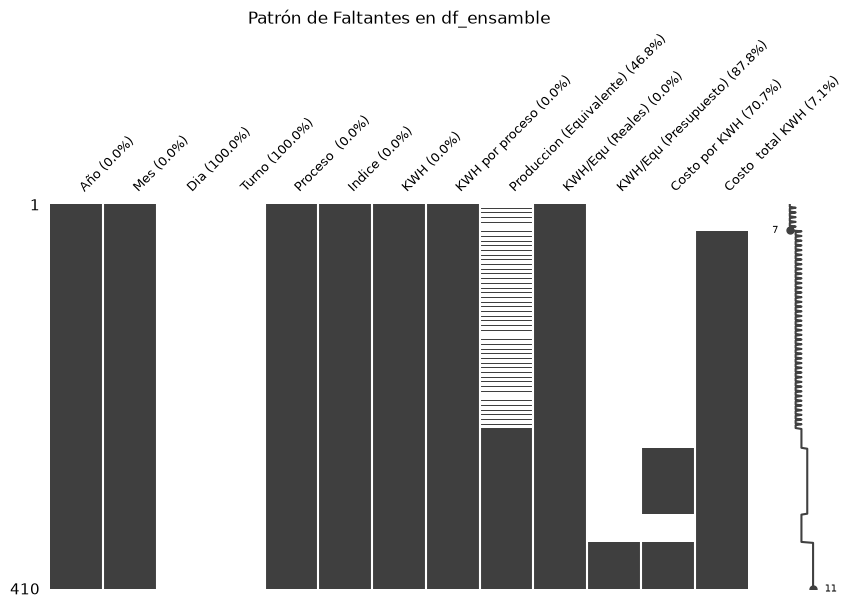

In [5]:
nan_diagnosis(df_ensamble, name="df_ensamble")

In [6]:
df_ensamble["Proceso "].unique()

<ArrowStringArray>
['Linea 1', 'Linea 2', 'Linea 3', 'Linea 4', 'Ensamble']
Length: 5, dtype: str

In [7]:
no_ensamble = df_ensamble[df_ensamble["Proceso "] != "Ensamble"]["Produccion (Equivalente)"]
solo_ensamble = df_ensamble[df_ensamble["Proceso "] == "Ensamble"]["Produccion (Equivalente)"]

print(f"Null values in non-Ensamble rows: {no_ensamble.isnull().sum()}")
print(f"Null values in Ensamble rows: {solo_ensamble.isnull().sum()}")

Null values in non-Ensamble rows: 192
Null values in Ensamble rows: 0


Parece ser que el consolidado por fabrica de este df es el proceso=Ensamble

In [8]:
df_ensamble[df_ensamble["Proceso "] != "OREC"]["Produccion (Equivalente)"] * df_ensamble[
    df_ensamble["Proceso "] != "OREC"
]["Indice"]

0              NaN
1              NaN
2              NaN
3              NaN
4           124270
          ...     
405    11077.81404
406    3929.402884
407            0.0
408    7658.022528
409     81625.8864
Length: 410, dtype: object

## Eliminar columas sin datos o constantes.

In [9]:
cols_to_drop = []
for col in df_ensamble.columns:
    if df_ensamble[col].isnull().all() or df_ensamble[col].nunique() == 1:
        cols_to_drop.append(col)
print(f"Columns to drop: {cols_to_drop}")

df_ensamble.drop(columns=cols_to_drop, inplace=True)

Columns to drop: ['Dia', 'Turno']


# Transformar al tipo correcto

In [10]:
df_ensamble.info()

<class 'pandas.DataFrame'>
RangeIndex: 410 entries, 0 to 409
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Año                       410 non-null    object
 1   Mes                       410 non-null    str   
 2   Proceso                   410 non-null    str   
 3   Indice                    410 non-null    object
 4   KWH                       410 non-null    object
 5   KWH por proceso           410 non-null    object
 6   Produccion (Equivalente)  218 non-null    object
 7   KWH/Equ (Reales)          410 non-null    object
 8   KWH/Equ (Presupuesto)     50 non-null     object
 9   Costo por KWH             120 non-null    object
 10  Costo  total KWH          381 non-null    object
dtypes: object(9), str(2)
memory usage: 39.4+ KB


In [11]:
df_ensamble = df_ensamble.rename(
    columns={"Costo  total KWH": "Costo total KWH", "Proceso ": "Proceso"}
)

In [12]:
df_ensamble["KWH"]

0      309181
1      309181
2      309181
3      309181
4      309181
        ...  
405    279900
406    279900
407    279900
408    279900
409    279900
Name: KWH, Length: 410, dtype: object

In [13]:
cols_numericas = [
    "Año",
    "Indice",
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]
for col in cols_numericas:
    df_ensamble[col] = (
        df_ensamble[col]
        .astype(str)
        .str.strip()
        # Nota: en esta base el punto es el separador DECIMAL (0 valores con
        # coma, 567 con punto), por eso NO se eliminan los puntos.
        .str.replace(",", ".", regex=False)  # Convierte coma decimal a punto
    )

# 2. Conversión a tipos de datos específicos

# Año e Indice a enteros (usando Int64 para soportar posibles valores nulos)
df_ensamble["Año"] = pd.to_numeric(df_ensamble["Año"], errors="coerce").astype("Int64")
df_ensamble["Indice"] = pd.to_numeric(df_ensamble["Indice"], errors="coerce")
# Columnas continuas/métricas a flotantes (float64)
cols_float = [
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

for col in cols_float:
    df_ensamble[col] = pd.to_numeric(df_ensamble[col], errors="coerce")

# Columnas de texto/categoría
df_ensamble["Mes"] = df_ensamble["Mes"].astype("category")  # o .astype(str)

# Verifica el resultado
df_ensamble.info()

<class 'pandas.DataFrame'>
RangeIndex: 410 entries, 0 to 409
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Año                       410 non-null    Int64   
 1   Mes                       410 non-null    category
 2   Proceso                   410 non-null    str     
 3   Indice                    410 non-null    float64 
 4   KWH                       410 non-null    int64   
 5   KWH por proceso           410 non-null    float64 
 6   Produccion (Equivalente)  218 non-null    float64 
 7   KWH/Equ (Reales)          410 non-null    float64 
 8   KWH/Equ (Presupuesto)     50 non-null     float64 
 9   Costo por KWH             120 non-null    float64 
 10  Costo total KWH           381 non-null    float64 
dtypes: Int64(1), category(1), float64(7), int64(1), str(1)
memory usage: 36.0 KB


In [14]:
meses_abr = {
    "ene": 1,
    "feb": 2,
    "mar": 3,
    "abr": 4,
    "may": 5,
    "jun": 6,
    "jul": 7,
    "ago": 8,
    "sep": 9,
    "oct": 10,
    "nov": 11,
    "dic": 12,
}

# 1. Limpiar texto y mapear a número
mes_num = (
    df_ensamble["Mes"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(".", "", regex=False)  # Quita puntos si vienen como 'Ene.'
    .map(meses_abr)
)

# 2. Crear la columna de Fecha (primer día de cada mes)
df_ensamble["Fecha"] = pd.to_datetime(
    {"year": df_ensamble["Año"], "month": mes_num, "day": 1}, errors="coerce"
)

In [15]:
# La hoja viene en orden cronologico, 5 filas por mes. Un solo bloque rompe el orden:
# las filas 10-14, entre nov-2019 y ene-2020, traen el anio 2020. Es diciembre de 2019
# mal digitado; sin corregirlo 2019-12 queda vacio y 2020-12 mezcla dos meses.
# Se corrige aqui, antes de repartir los dias, para que cada mes quede con sus 5 filas.
FILAS_POR_MES = 5
bloque = df_ensamble.index // FILAS_POR_MES
calendario = pd.date_range(df_ensamble["Fecha"].iloc[0], periods=bloque.max() + 1, freq="MS")
esperada = pd.Series(calendario[bloque], index=df_ensamble.index)

mal = df_ensamble["Fecha"] != esperada
desfase = (df_ensamble.loc[mal, "Fecha"] - esperada[mal]).dt.days

# Si la hoja cambia y el patron deja de ser este, mejor fallar que re-fechar a ciegas
assert mal.sum() == FILAS_POR_MES, "se esperaba un unico bloque mal rotulado"
assert desfase.between(365, 366).all(), "el desfase no es de un anio exacto"

print(
    f"filas corregidas: {list(df_ensamble.index[mal])}  "
    f"{df_ensamble.loc[mal, 'Fecha'].iloc[0]:%Y-%m} -> {esperada[mal].iloc[0]:%Y-%m}"
)
df_ensamble.loc[mal, "Año"] = esperada[mal].dt.year
df_ensamble.loc[mal, "Fecha"] = esperada[mal]

filas corregidas: [10, 11, 12, 13, 14]  2020-12 -> 2019-12


In [16]:
base_fecha = pd.to_datetime(df_ensamble["Fecha"])

# 2. Número de aparición (0, 1, 2, ...) dentro de cada grupo Año-Mes
k = df_ensamble.groupby(["Año", "Mes"]).cumcount()

# 3. Total de registros por cada grupo Año-Mes
n = df_ensamble.groupby(["Año", "Mes"])["Fecha"].transform("count")

# 4. Total de días del mes específico (considera años bisiestos automáticamente)
dias_en_mes = base_fecha.dt.days_in_month

# 5. Calcular el día correspondiente con distribución uniforme entre el día 1 y el último día del
# mes
# Para n == 1 el incremento es 0 (queda día 1). Para n > 1 el último registro queda cerca del final
# del mes.
incremento_dias = (k * (dias_en_mes - 1) / (n - 1).replace(0, 1)).round()

# 6. Sumar los días a la fecha base (día 1)
df_ensamble["Fecha"] = base_fecha + pd.to_timedelta(incremento_dias, unit="D")

In [17]:
df_ensamble["Fecha"]

0     2019-10-01
1     2019-10-09
2     2019-10-16
3     2019-10-23
4     2019-10-31
         ...    
405   2026-07-01
406   2026-07-09
407   2026-07-16
408   2026-07-23
409   2026-07-31
Name: Fecha, Length: 410, dtype: datetime64[us]

# Split the data

In [18]:
df_ensamble.shape

(410, 12)

In [19]:
# El split tiene que ser temporal, asi que las filas se ordenan por fecha antes
# de partirlas. df_ensamble no se toca: las secciones de series de tiempo dependen
# de el. El indice original se conserva, para poder rastrear cada fila.
orden = df_ensamble.sort_values("Fecha")

X = orden.drop(columns=["Mes", "Año", "Produccion (Equivalente)"])
y = orden["Produccion (Equivalente)"]
X.shape, y.shape

((410, 9), (410,))

In [20]:
# Split temporal: el ultimo fold de TimeSeriesSplit deja todo el pasado en train y el
# futuro en test.
CORTE = "2025-01-01"
test_size = int((X["Fecha"] >= CORTE).sum())  # alineado a inicio de mes

# n_splits=2 es el minimo que admite sklearn; solo interesa el ultimo fold, el que
# entrena con todo lo anterior al corte. El corte se expresa en fechas y no en un
# numero de filas para que la frontera caiga siempre en un inicio de mes.
tscv = TimeSeriesSplit(n_splits=2, test_size=test_size)
*_, (i_train, i_test) = tscv.split(X)

X_train, X_test = X.iloc[i_train], X.iloc[i_test]
y_train, y_test = y.iloc[i_train], y.iloc[i_test]

In [21]:
print(
    f"train {X_train['Fecha'].min():%Y-%m} -> {X_train['Fecha'].max():%Y-%m}"
    f"  ({len(X_train)} filas)"
)
print(
    f"test  {X_test['Fecha'].min():%Y-%m} -> {X_test['Fecha'].max():%Y-%m}  ({len(X_test)} filas)"
)
print(
    f"sin solape: {X_train['Fecha'].max() < X_test['Fecha'].min()}  |  "
    f"target no nulo: train={y_train.notna().sum()} test={y_test.notna().sum()}"
)
X_train.shape, X_test.shape

train 2019-10 -> 2024-12  (315 filas)
test  2025-01 -> 2026-07  (95 filas)
sin solape: True  |  target no nulo: train=123 test=95


((315, 9), (95, 9))

In [22]:
df_train = pd.concat([X_train, y_train], axis=1)

# Iniciar el análisis exploratorio de datos (EDA) con las funciones personalizadas

In [23]:
df_train.columns

Index(['Proceso', 'Indice', 'KWH', 'KWH por proceso', 'KWH/Equ (Reales)',
       'KWH/Equ (Presupuesto)', 'Costo por KWH', 'Costo total KWH', 'Fecha',
       'Produccion (Equivalente)'],
      dtype='str')

D:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 5 distinct values across 315 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)
findfont: Failed to find font weight medium for Arial, now using 400.


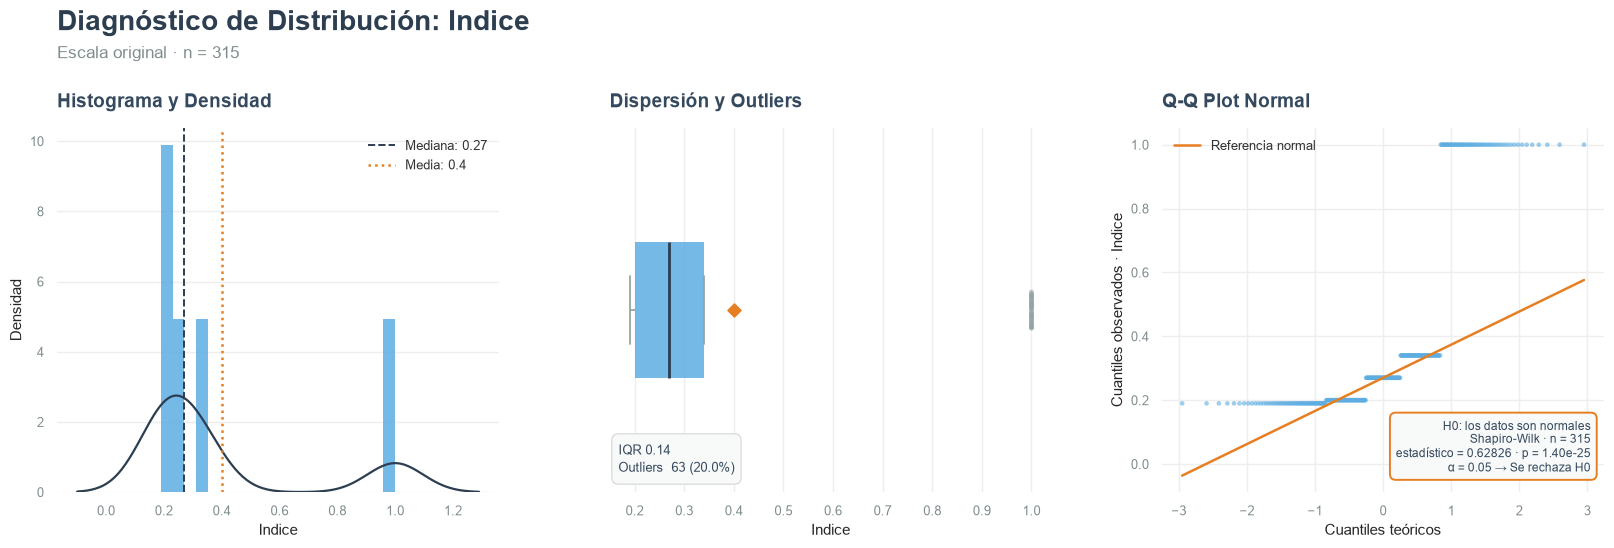

D:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 63 distinct values across 315 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


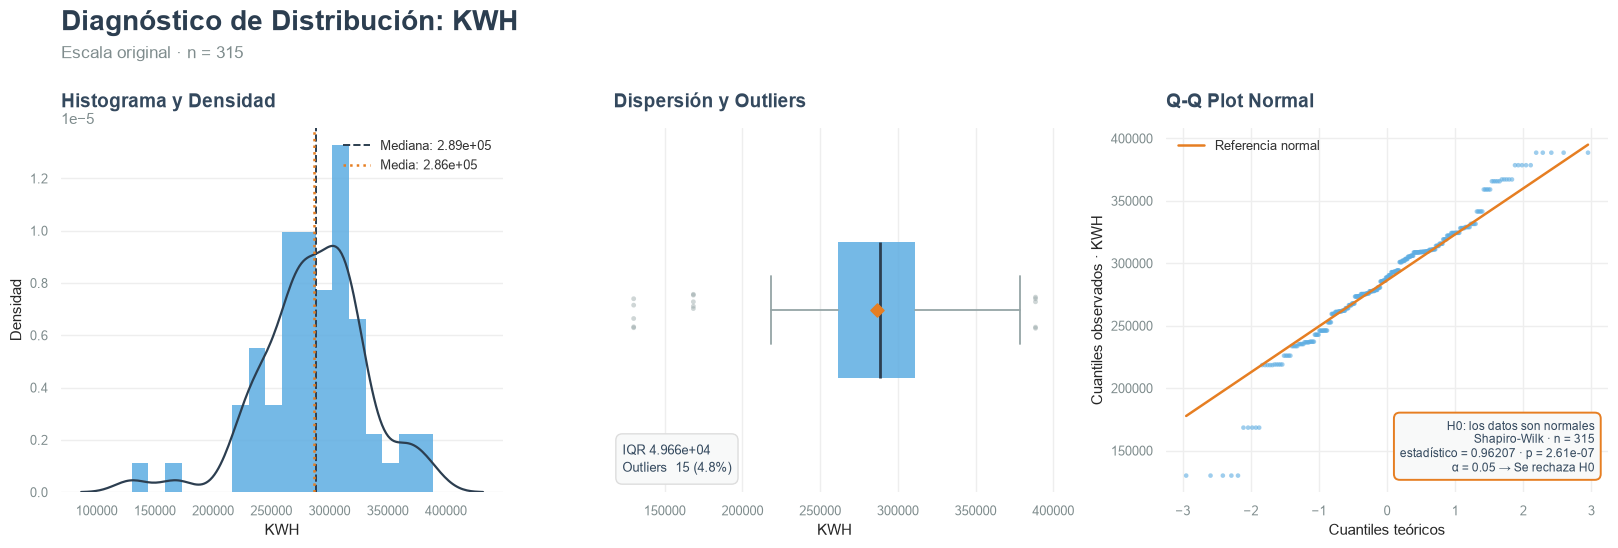

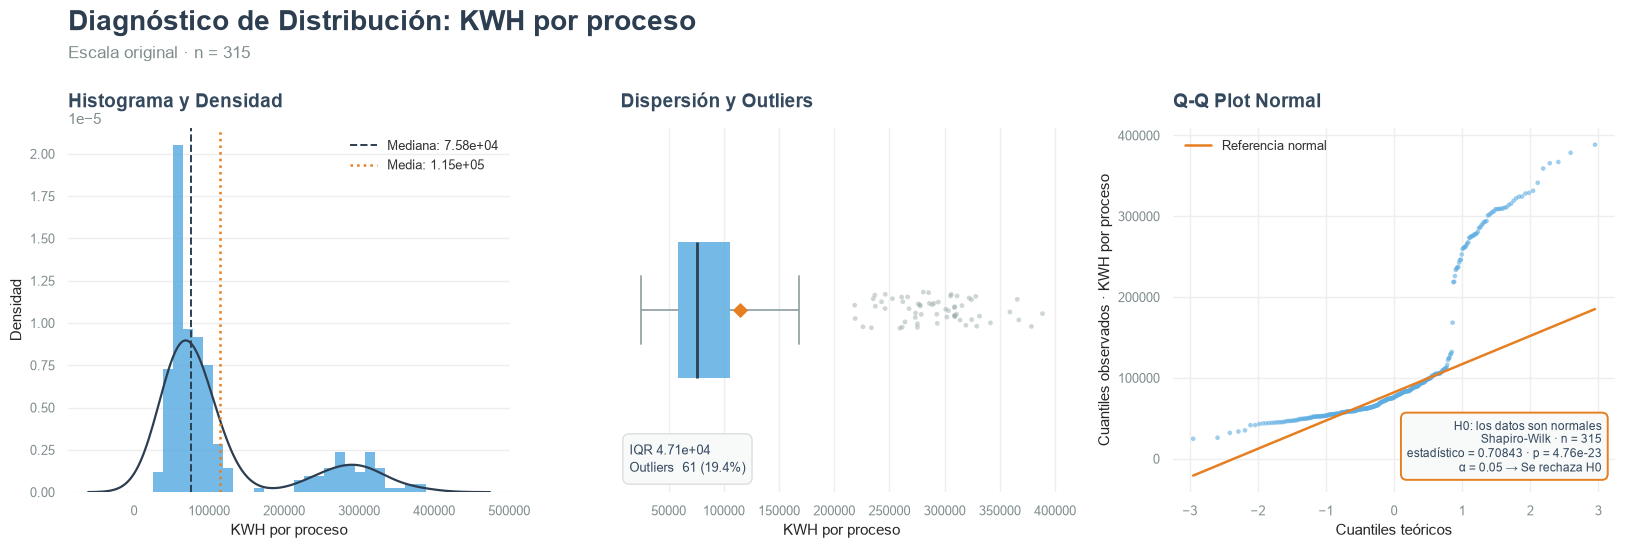

D:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 124 distinct values across 315 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


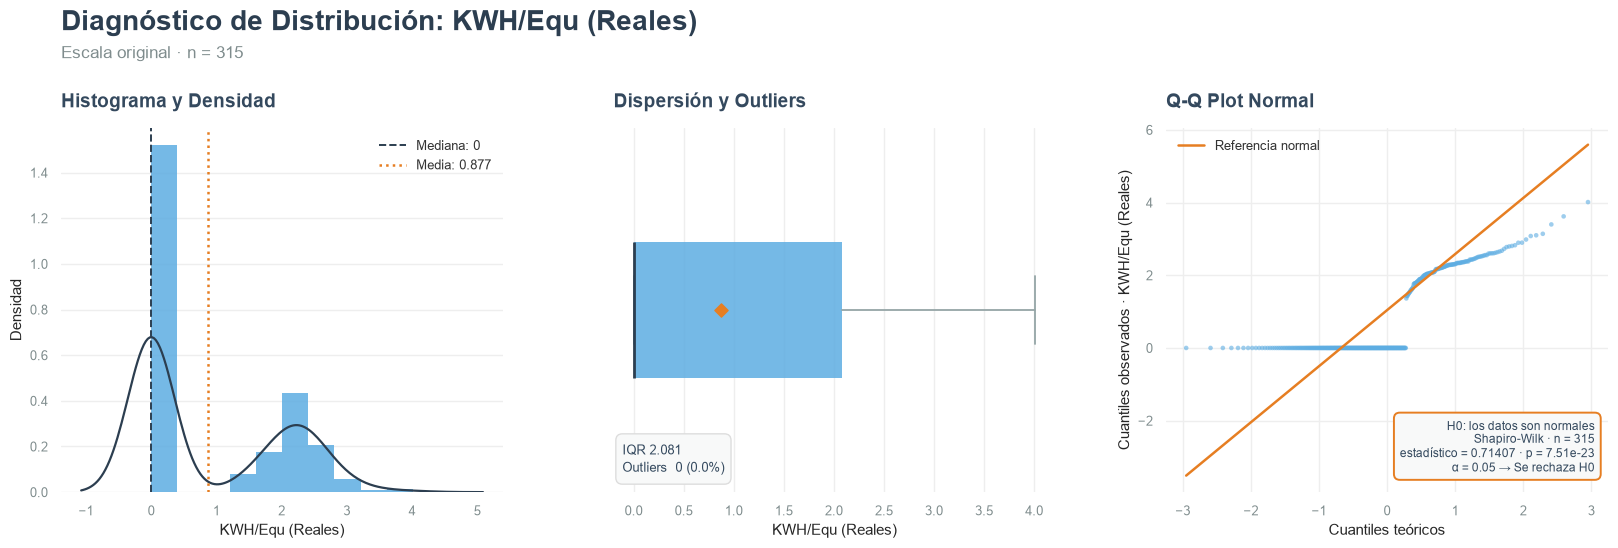

KWH/Equ (Presupuesto): 0 valores validos en train, se omite (se registra desde una fecha posterior al corte)


D:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 11 distinct values across 55 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


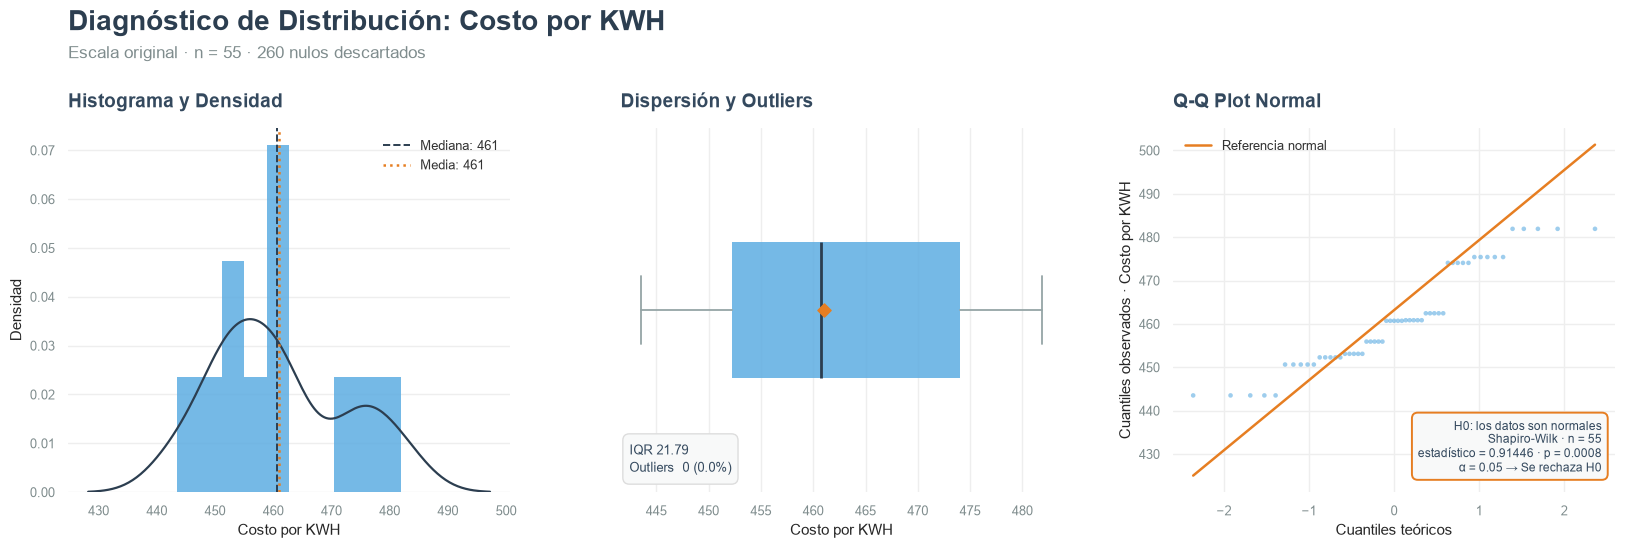

D:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 56 distinct values across 286 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


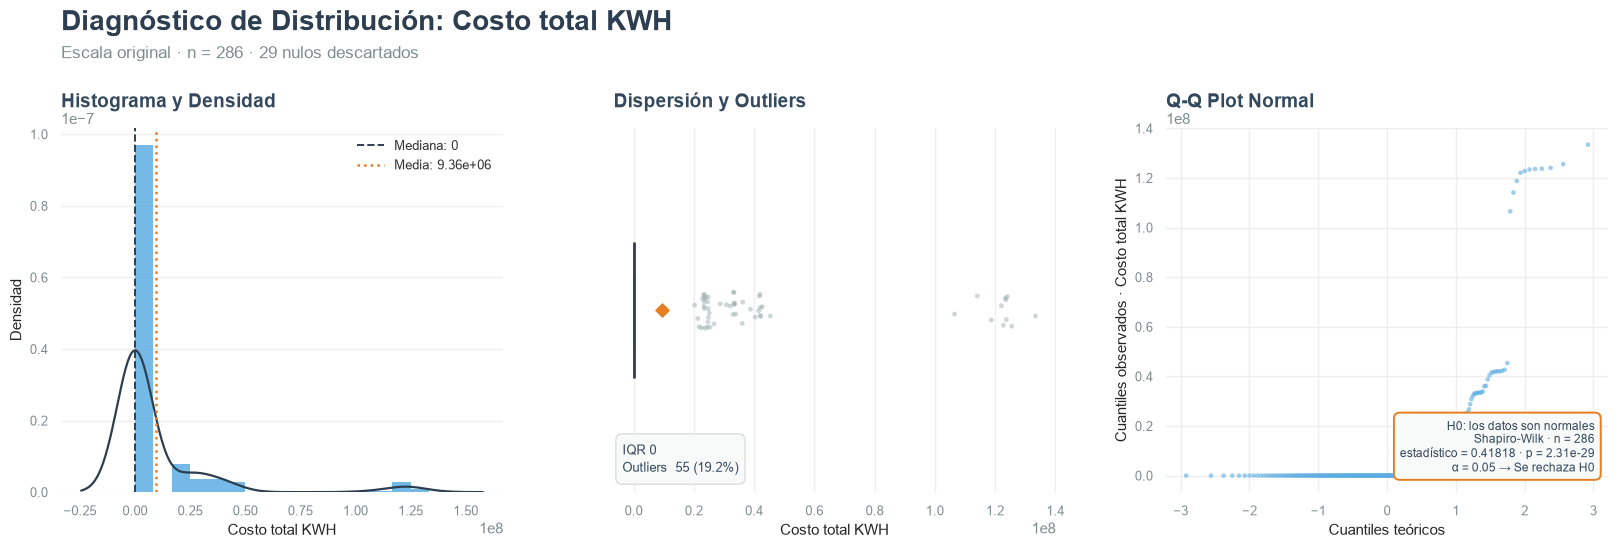

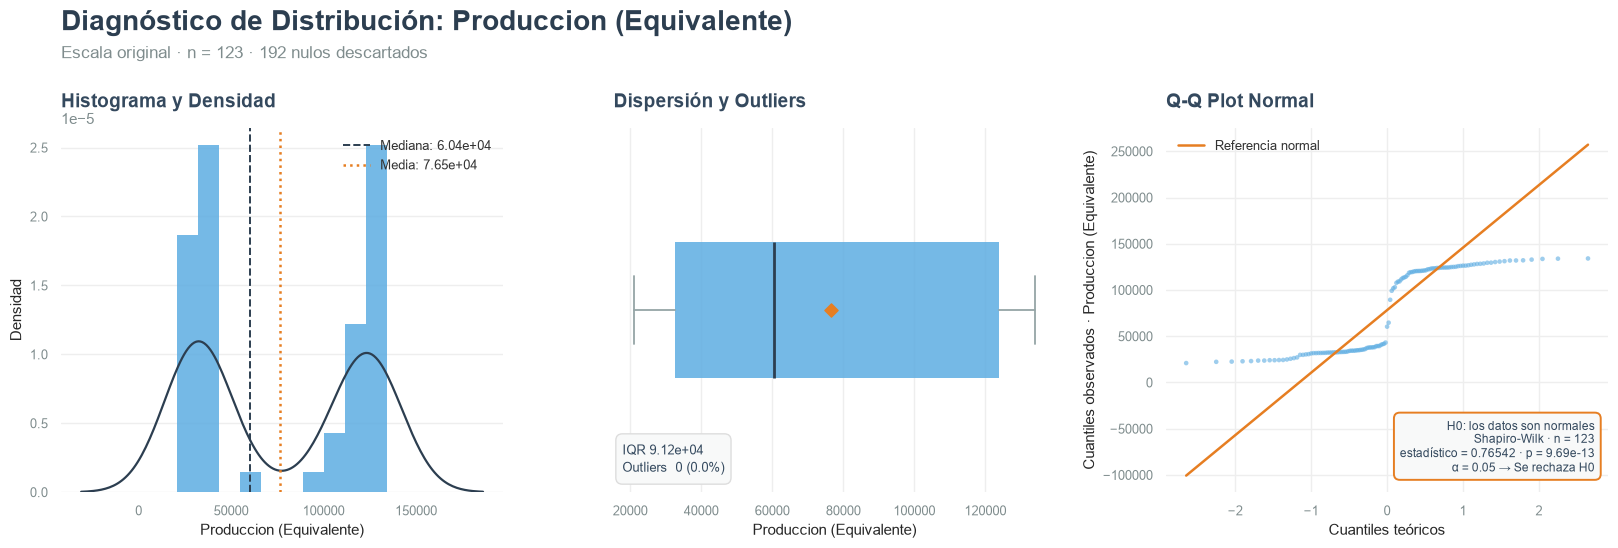

In [24]:
# El split es temporal, asi que una columna que empieza a registrarse tarde puede
# quedar vacia en train: KWH/Equ (Presupuesto) arranca en 2025-10, ya dentro de la
# ventana de test. normality_report exige un minimo de 8 valores, asi que se avisa
# y se sigue en vez de cortar el notebook.
MIN_VALIDOS = 8

for col in df_train.columns:
    if df_train[col].dtype == "int64" or df_train[col].dtype == "float64":
        validos = df_train[col].dropna().size
        if validos < MIN_VALIDOS:
            print(
                f"{col}: {validos} valores validos en train, se omite "
                f"(se registra desde una fecha posterior al corte)"
            )
            continue
        normality_report(df_train, col)

`Produccion (Equivalente)` muestra dos picos porque mezcla dos escalas: el total de planta
(filas `Ensamble`) y el valor de cada linea. Conviene leerla separada por proceso, para no
sacar conclusiones de una distribucion que en realidad son dos.

<Axes: title={'left': 'Distribución de Proceso'}, xlabel='Proceso', ylabel='Conteo'>

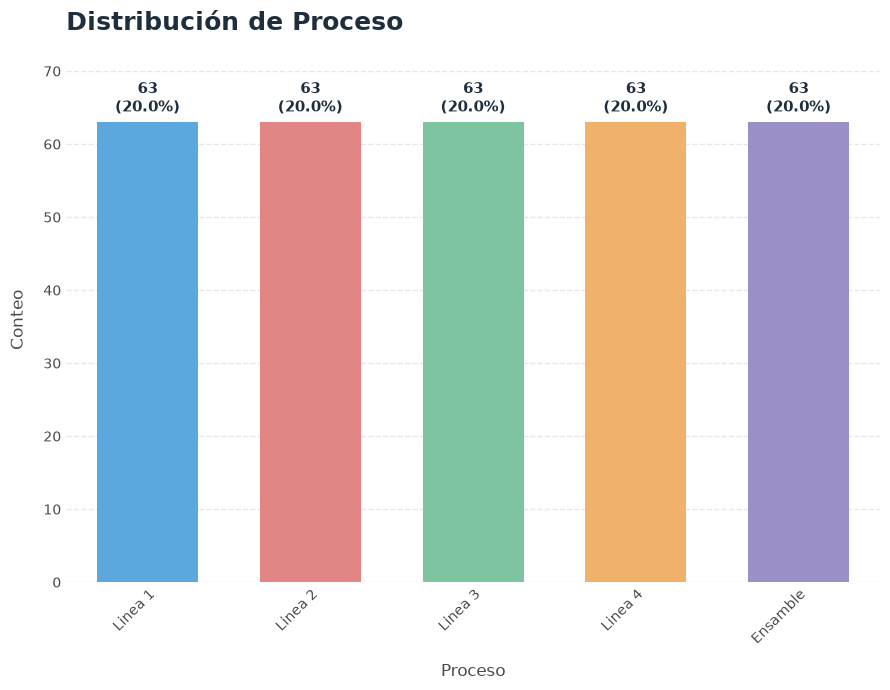

In [25]:
fancy_bars(df_train, "Proceso", labels="both", rot=45)

## Ahondando en los atipicos

In [26]:
cols = ["Costo total KWH", "Costo por KWH", "KWH/Equ (Reales)", "KWH por proceso"]

# Los ceros y nulos son estructurales (proceso sin registro), no mediciones:
# incluirlos deformaria el IQR. Todo se calcula sobre valores > 0.
resumen = []
for col in cols:
    s = df_ensamble[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    resumen.append(
        {
            "columna": col,
            "n": len(s),
            "atipicos": len(atipicos),
            "mediana": s.median(),
            "maximo": s.max(),
            "max/mediana": s.max() / s.median(),
        }
    )

pd.DataFrame(resumen).round(1)

,columna,n,atipicos,mediana,maximo,max/mediana
0,Costo total KWH,120,24,33390473.9,155090957.5,4.6
1,Costo por KWH,120,0,518.2,568.5,1.1
2,KWH/Equ (Reales),209,12,2.3,5.8,2.6
3,KWH por proceso,410,79,73852.7,388552.0,5.3


In [27]:
# Algunos valores atipicos concretos (los 5 mas altos de cada columna)
for col in cols:
    s = df_ensamble[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    print(f"{col} -> {len(atipicos)} atipicos")
    print(atipicos.nlargest(5).to_string())

Costo total KWH -> 24 atipicos
329    1.550910e+08
409    1.482288e+08
364    1.453902e+08
319    1.403276e+08
289    1.334069e+08
Costo por KWH -> 0 atipicos
Series([], )
KWH/Equ (Reales) -> 12 atipicos
385    5.818852
389    5.374443
99     4.013277
394    3.806766
388    3.759890
KWH por proceso -> 79 atipicos
64    388552.0
49    378529.0
74    367130.0
69    365666.0
54    359084.0


Costo total KWH        mediana=  33,390,473.9  max= 155,090,957.5  ordenes=0.67
Costo por KWH          mediana=         518.2  max=         568.5  ordenes=0.04
KWH/Equ (Reales)       mediana=           2.3  max=           5.8  ordenes=0.41
KWH por proceso        mediana=      73,852.7  max=     388,552.0  ordenes=0.72


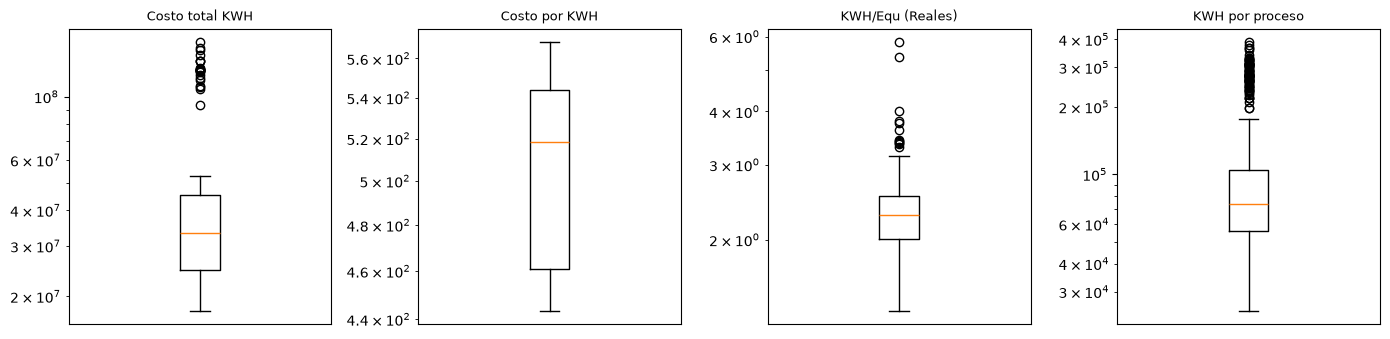

In [28]:
# Ordenes de magnitud entre el maximo y la mediana
for col in cols:
    s = df_ensamble.loc[df_ensamble[col] > 0, col].dropna()
    print(
        f"{col:<22} mediana={s.median():>14,.1f}  max={s.max():>14,.1f}  "
        f"ordenes={np.log10(s.max() / s.median()):.2f}"
    )

# Escala log: si la caja se ve aplastada contra el eje, la cola abarca ordenes de magnitud
fig, axes = plt.subplots(1, len(cols), figsize=(14, 3.5))
for ax, col in zip(axes, cols, strict=False):
    ax.boxplot(df_ensamble.loc[df_ensamble[col] > 0, col].dropna())
    ax.set_yscale("log")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [29]:
# Metricas explicitas del resumen de abajo
filas = []
for col in cols:
    s = df_ensamble[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    # Cuantos de los atipicos son filas de total de planta: la columna mezcla la escala
    # de la planta (Ensamble) con la de cada linea
    de_planta = df_ensamble.loc[atipicos.index, "Proceso"] == "Ensamble"
    filas.append(
        {
            "columna": col,
            "n": len(s),
            "atipicos": len(atipicos),
            "atipicos_en_Ensamble": int(de_planta.sum()),
            "mediana": s.median(),
            "maximo": s.max(),
            "max_sobre_mediana": s.max() / s.median(),
            "ordenes": np.log10(s.max() / s.median()),
            # Ceros y nulos contados sobre df_ensamble completo
            "ceros": int((df_ensamble[col] == 0).sum()),
            "nulos": int(df_ensamble[col].isna().sum()),
        }
    )

metricas_atipicos = pd.DataFrame(filas).round(2)
print(f"df_ensamble: {len(df_ensamble)} filas | df_train (temporal): {len(df_train)} filas")
metricas_atipicos

df_ensamble: 410 filas | df_train (temporal): 315 filas


,columna,n,atipicos,atipicos_en_Ensamble,mediana,maximo,max_sobre_mediana,ordenes,ceros,nulos
0,Costo total KWH,120,24,24,33390473.94,1.550910e+08,4.64,0.67,261,29
1,Costo por KWH,120,0,0,518.21,5.684600e+02,1.10,0.04,0,290
2,KWH/Equ (Reales),209,12,7,2.28,5.820000e+00,2.55,0.41,201,0
3,KWH por proceso,410,79,79,73852.69,3.885520e+05,5.26,0.72,0,0


### Resumen de atipicos

**1. Atipicos por IQR** (solo valores > 0, sobre las 410 filas):

| columna | mediana | maximo | max/mediana | atipicos | de `Ensamble` |
|---|---|---|---|---|---|
| `Costo total KWH` | 33,390,473.9 | 155,090,957.5 | 4.64x | 24 | 24 |
| `Costo por KWH` | 518.2 | 568.5 | 1.10x | 0 | 0 |
| `KWH/Equ (Reales)` | 2.28 | 5.82 | 2.55x | 12 | 7 |
| `KWH por proceso` | 73,852.7 | 388,552.0 | 5.26x | 79 | 79 |

**2. Ninguna columna crece por ordenes de magnitud.** La mayor razon es 5.26x (0.72
ordenes) y `KWH/Equ (Reales)` se queda en 2.55x (0.41). No hay un registro aislado como
el de OREC.

**3. Los atipicos de `KWH por proceso` y `Costo total KWH` son las filas de planta.** Los
79 y los 24 son filas `Ensamble`: la columna mezcla el total de planta con el valor de cada
linea y el IQR marca la escala mayor. No son mediciones anomalas.

**4. `Costo por KWH` no tiene atipicos** y casi no varia (1.10x). Es una tarifa, no una
medicion del proceso.

**5. Ceros y nulos son estructurales** y se excluyeron del calculo: `Costo total KWH` tiene
261 ceros y 29 nulos, `KWH/Equ (Reales)` 201 ceros y `Costo por KWH` 290 nulos.

In [30]:
# En OREC habia un registro que crecia ordenes de magnitud y se retiraba. Aqui la
# pregunta es si hace falta: se arma la misma copia sin el maximo de KWH/Equ (Reales)
# para medir cuanto cambia el diagnostico. df_ensamble no se modifica y la copia no
# se usa mas abajo.
df_sin_maximo = df_ensamble.drop(df_ensamble["KWH/Equ (Reales)"].idxmax())

Costo total KWH        mediana=  33,372,532.5  max= 155,090,957.5  ordenes=0.67
Costo por KWH          mediana=         513.1  max=         568.5  ordenes=0.04
KWH/Equ (Reales)       mediana=           2.3  max=           5.4  ordenes=0.37
KWH por proceso        mediana=      73,869.0  max=     388,552.0  ordenes=0.72


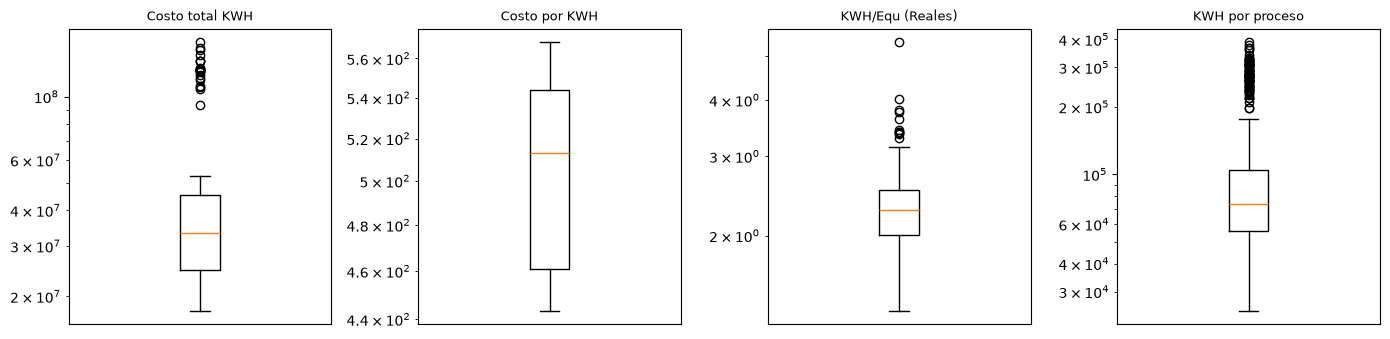

In [31]:
# Mismo analisis que arriba, ahora sobre el dataset sin el valor maximo
for col in cols:
    s = df_sin_maximo.loc[df_sin_maximo[col] > 0, col].dropna()
    print(
        f"{col:<22} mediana={s.median():>14,.1f}  max={s.max():>14,.1f}  "
        f"ordenes={np.log10(s.max() / s.median()):.2f}"
    )

fig, axes = plt.subplots(1, len(cols), figsize=(14, 3.5))
for ax, col in zip(axes, cols, strict=False):
    ax.boxplot(df_sin_maximo.loc[df_sin_maximo[col] > 0, col].dropna())
    ax.set_yscale("log")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [32]:
# Las dos mitades de la comparacion se calculan aqui: df_ensamble no se modifica.
def ordenes(d: pd.DataFrame, col: str) -> float:
    """Ordenes de magnitud entre el maximo y la mediana de `col`, sobre valores > 0."""
    s = d.loc[d[col] > 0, col].dropna()
    return np.log10(s.max() / s.median())


comparacion = pd.DataFrame(
    [
        {
            "columna": col,
            "ordenes_antes": round(ordenes(df_ensamble, col), 2),
            "ordenes_despues": round(ordenes(df_sin_maximo, col), 2),
            # criterio: < 1 orden. Si ya se cumplia antes, no habia nada que corregir
            "ya_cumplia_antes": ordenes(df_ensamble, col) < 1,
        }
        for col in cols
    ]
)
comparacion

,columna,ordenes_antes,ordenes_despues,ya_cumplia_antes
0,Costo total KWH,0.67,0.67,True
1,Costo por KWH,0.04,0.04,True
2,KWH/Equ (Reales),0.41,0.37,True
3,KWH por proceso,0.72,0.72,True


In [33]:
# Metricas explicitas del resumen de abajo.
# El 'antes' es df_ensamble completo y el 'despues' la copia sin el valor maximo.
antes = df_ensamble
despues = df_sin_maximo


def resumen_iqr(d: pd.DataFrame) -> pd.DataFrame:
    """Tabla IQR por columna: atipicos, maximo, razon max/mediana y ordenes."""
    filas = []
    for col in cols:
        s = d[col].dropna()
        s = s[s > 0]
        q1, q3 = s.quantile([0.25, 0.75])
        atipicos = s[s > q3 + 1.5 * (q3 - q1)]
        filas.append(
            {
                "columna": col,
                "atipicos": len(atipicos),
                "maximo": s.max(),
                "ratio": s.max() / s.median(),
                "ordenes": np.log10(s.max() / s.median()),
            }
        )
    return pd.DataFrame(filas).set_index("columna")


a, b = resumen_iqr(antes), resumen_iqr(despues)
metricas_verificacion = (
    a.join(b, lsuffix="_antes", rsuffix="_despues")
    .assign(ya_cumplia_antes=lambda t: t["ordenes_antes"] < 1)
    .reset_index()
    .round(2)
)

# El registro del maximo, junto al total de planta de ese mismo mes
i_max = df_ensamble["KWH/Equ (Reales)"].idxmax()
mismo_mes = df_ensamble["Fecha"].dt.to_period("M") == df_ensamble.loc[i_max, "Fecha"].to_period("M")
de_interes = df_ensamble["Proceso"].isin([df_ensamble.loc[i_max, "Proceso"], "Ensamble"])
registro_maximo = df_ensamble.loc[
    mismo_mes & de_interes,
    ["Fecha", "Proceso", "KWH por proceso", "Produccion (Equivalente)", "KWH/Equ (Reales)"],
].round(2)

print(f"filas: {len(antes)} -> {len(despues)} (la copia quita {len(antes) - len(despues)})")
display(registro_maximo)
metricas_verificacion

filas: 410 -> 409 (la copia quita 1)


D:\Temp\ipykernel_20300\1926848230.py:42: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Fecha,Proceso,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales)
385,2026-03-01,Linea 1,67098.32,11531.20,5.82
389,2026-03-31,Ensamble,197348.00,36719.71,5.37


,columna,atipicos_antes,maximo_antes,ratio_antes,ordenes_antes,atipicos_despues,maximo_despues,ratio_despues,ordenes_despues,ya_cumplia_antes
0,Costo total KWH,24,1.550910e+08,4.64,0.67,24,1.550910e+08,4.65,0.67,True
1,Costo por KWH,0,5.684600e+02,1.10,0.04,0,5.684600e+02,1.11,0.04,True
2,KWH/Equ (Reales),12,5.820000e+00,2.55,0.41,11,5.370000e+00,2.36,0.37,True
3,KWH por proceso,79,3.885520e+05,5.26,0.72,79,3.885520e+05,5.26,0.72,True


### Verificacion: no hay registro extremo que quitar

- **No habia nada que corregir.** Las cuatro columnas ya estaban por debajo de 1 orden de
  magnitud antes de quitar nada (`ya_cumplia_antes` es verdadero en todas).
- **Quitar el maximo casi no cambia el diagnostico.** `KWH/Equ (Reales)` pasa de 0.41 a
  0.37 ordenes (de 2.55x a 2.36x) y de 12 a 11 atipicos; las otras tres columnas quedan
  en los mismos ordenes (0.67, 0.04 y 0.72).
- **El maximo es un mes real, no un error.** Es `Linea 1` en 2026-03: 67,098.32 kWh para
  11,531.20 equivalentes (5.82). Ese mismo mes el total de planta marca 5.37: produjo poco
  toda la planta, no solo esa linea.
- **Por eso no se elimina ninguna fila.** La copia de 409 filas solo sirve para esta
  comparacion; el resto del notebook usa las 410.

## Series de tiempo de las variables numericas

La base solo tiene `Año` y `Mes`: la columna `Fecha` reparte los registros entre los dias
del mes de forma artificial, asi que la granularidad real es **mensual**. Cada punto es el
promedio de los 5 procesos de ese mes. La serie llega hasta **2026-07**, que esta completo.

Estas secciones usan **todo el historico**, no solo la ventana de train: son
descriptivas, no alimentan ningun modelo, y el cambio que analizan ocurre justo en
2025-2026. La banda gris de cada grafico marca la ventana de test (desde `2025-01`),
para que se vea que parte de la serie quedo fuera del entrenamiento.

In [34]:
num_cols = [
    "Indice",
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

# Granularidad real = mensual; promedio entre los 5 procesos de cada mes.
# Fecha reparte el dia dentro del mes de forma artificial, asi que se agrupa por el
# inicio de mes. No hace falta recortar la cola: 2026-07 trae sus 5 filas.
mes_completo = df_ensamble["Fecha"].dt.to_period("M").dt.to_timestamp()
serie = df_ensamble.groupby(mes_completo)[num_cols].mean()

serie.shape

(82, 8)

D:\Temp\ipykernel_20300\910355444.py:74: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  plt.tight_layout(rect=[0, 0, 1, 0.97])


D:\Externado\Catch_2026\clarios_app\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


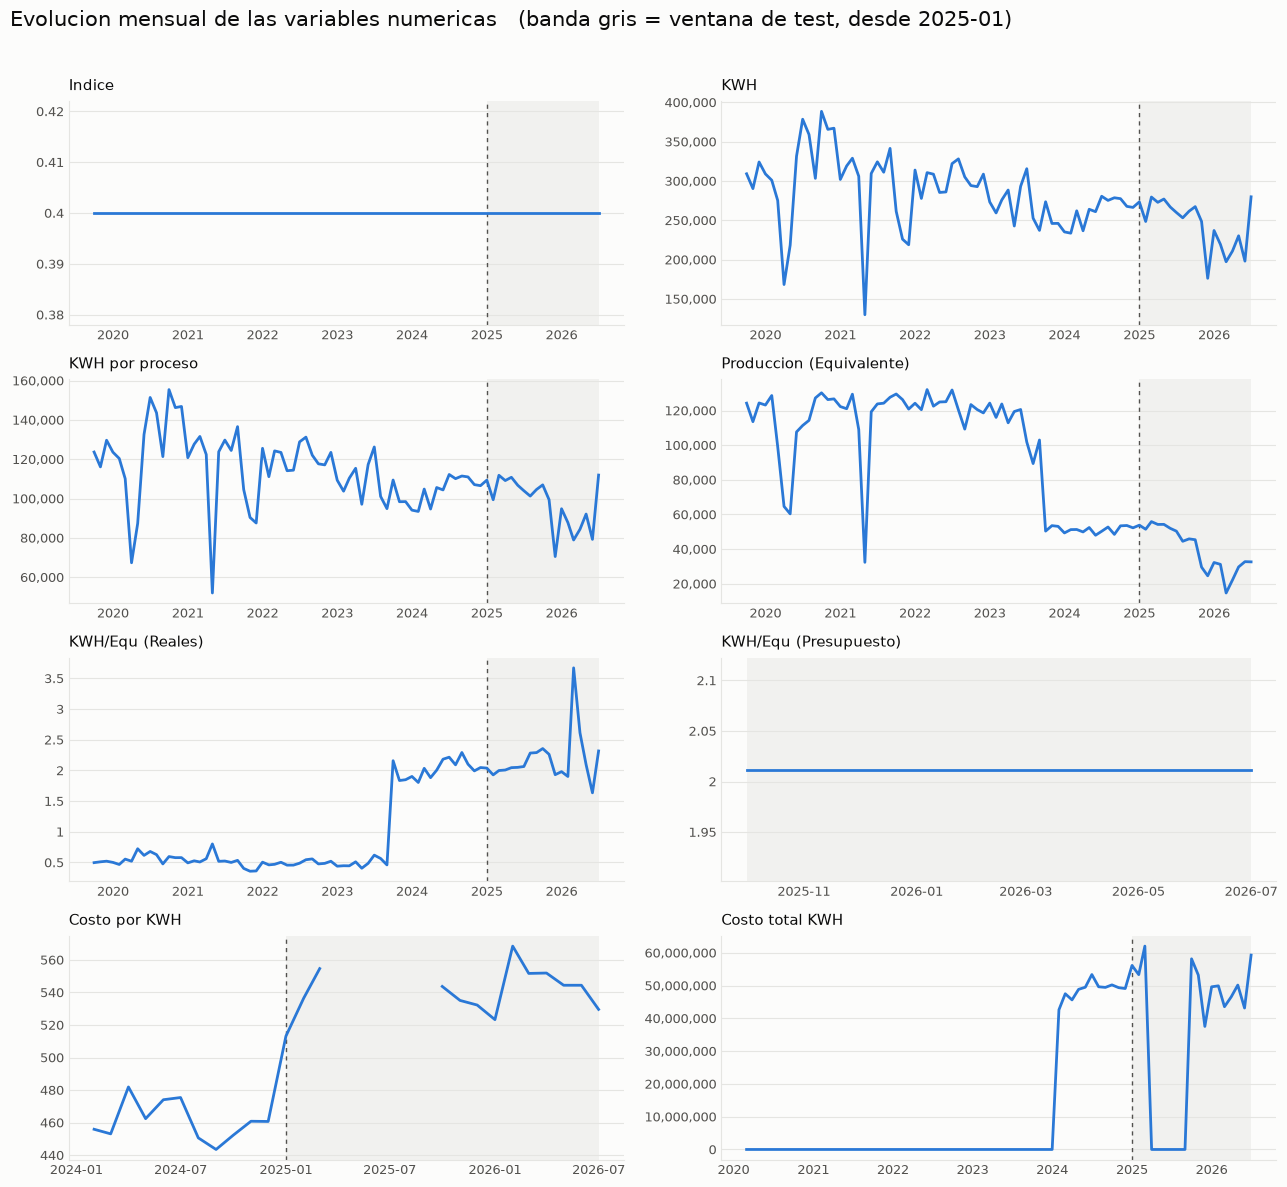

In [35]:
import matplotlib.dates as mdates

# Paleta validada (skill dataviz): linea, superficie, tinta y grilla
LINEA, SUPERFICIE = "#2a78d6", "#fcfcfb"
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e5e5e2"

# Por encima de este valor el eje se formatea con separador de miles y sin decimales;
# por debajo, con 3 cifras significativas (si no, 1.5, 2 y 2.5 se rotulan todos '2')
UMBRAL_MILES = 1000
# Un panel con menos historia que esto satura el eje de fechas con el formato por
# defecto, que rotula cada marca como AAAA-MM
PANEL_CORTO = pd.Timedelta(days=3 * 365)

# Las series cubren todo el historico, pero el split es temporal: esta funcion sombrea
# la ventana de test para que se vea que parte quedo fuera del entrenamiento.
# CORTE viene de la celda del split, asi la banda sigue al corte y no se repite el dato.
CORTE_TS = pd.Timestamp(CORTE)


def marcar_test(
    ax: plt.Axes, desde: pd.Timestamp, hasta: pd.Timestamp, etiqueta: bool = False
) -> None:
    """Sombrea la ventana de test, recortada al rango que ya ocupa la serie."""
    # El rango se pasa explicito: ax.get_xlim() devuelve numeros de fecha de matplotlib
    # y mezclarlos con un Timestamp en axvspan falla. Recortar a [desde, hasta] evita
    # que la banda estire el eje de un panel cuyos datos empiezan despues del corte
    # (KWH/Equ (Presupuesto) arranca en 2025-10, ya dentro de test).
    if hasta < CORTE_TS:
        return  # el panel termina antes del corte: no hay ventana de test que marcar
    ax.axvspan(max(CORTE_TS, desde), hasta, color=GRILLA, alpha=0.45, zorder=0, linewidth=0)
    if desde <= CORTE_TS:
        ax.axvline(CORTE_TS, color=TINTA_SUAVE, linewidth=1, linestyle=(0, (3, 3)), zorder=2)
    if etiqueta:
        ax.annotate(
            "ventana de test",
            xy=(CORTE_TS, 1),
            xycoords=("data", "axes fraction"),
            xytext=(5, -12),
            textcoords="offset points",
            color=TINTA_SUAVE,
            fontsize=8,
        )


fig, axes = plt.subplots(4, 2, figsize=(13, 12), facecolor=SUPERFICIE)
fig.suptitle(
    "Evolucion mensual de las variables numericas   (banda gris = ventana de test, desde 2025-01)",
    fontsize=15,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)

for ax, col in zip(axes.ravel(), num_cols, strict=False):
    ax.plot(serie.index, serie[col], color=LINEA, linewidth=2, zorder=3)
    visible = serie[col].replace(0, np.nan).dropna()
    marcar_test(ax, visible.index[0], visible.index[-1])
    ax.set_title(col, fontsize=10.5, color=TINTA, loc="left", pad=8)
    ax.set_facecolor(SUPERFICIE)
    ax.grid(axis="y", color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRILLA)
    ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
    ax.yaxis.set_major_formatter(
        lambda v, _: f"{v:,.0f}" if abs(v) >= UMBRAL_MILES else f"{v:,.3g}"
    )
    trazado = serie[col].dropna()
    if trazado.index[-1] - trazado.index[0] < PANEL_CORTO:
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=6))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [36]:
# Metricas explicitas del resumen de abajo
mes = df_ensamble["Fecha"].dt.to_period("M").dt.to_timestamp()
es_planta = df_ensamble["Proceso"] == "Ensamble"

# 1) Cobertura: desde cuando hay dato y en cuantos meses
cobertura = pd.DataFrame(
    [
        {
            "variable": c,
            "desde": mes[df_ensamble[c] > 0].min(),
            "meses_con_dato": mes[df_ensamble[c] > 0].nunique(),
            "meses_totales": mes.nunique(),
        }
        for c in num_cols
    ]
)

# 2) Calendario: tras corregir el diciembre mal rotulado no quedan huecos ni meses dobles
meses = sorted(mes.unique())
esperados = pd.date_range(min(meses), max(meses), freq="MS")
filas_por_mes = mes.value_counts()
print(
    f"meses {len(meses)} de {len(esperados)} esperados -> "
    f"sin huecos: {len(meses) == len(esperados)}"
)
print(
    f"de {min(meses):%Y-%m} a {max(meses):%Y-%m} | "
    f"filas por mes: minimo {filas_por_mes.min()}, maximo {filas_por_mes.max()}"
)

# 3) Desde cuando reportan produccion las lineas: ahi cambia lo que promedia cada mes
prod_lineas = mes[~es_planta & (df_ensamble["Produccion (Equivalente)"] > 0)]
print(f"produccion por linea desde {prod_lineas.min():%Y-%m} ({prod_lineas.nunique()} meses)")

# 4) Las dos agregaciones lado a lado: promedio por proceso vs total de planta (Ensamble)
por_proceso = df_ensamble.groupby(mes)[
    ["KWH", "Produccion (Equivalente)", "KWH/Equ (Reales)"]
].mean()
solo_planta = df_ensamble[es_planta]
planta_ts = solo_planta.groupby(mes[es_planta])[
    ["KWH por proceso", "Produccion (Equivalente)", "KWH"]
].mean()
planta_ts["KWH/Equ"] = planta_ts["KWH por proceso"] / planta_ts["Produccion (Equivalente)"]


def cambio(valores: pd.Series, a: int = 2020, b: int = 2025) -> tuple[float, float, float]:
    """Media de `valores` en los anios `a` y `b`, y el cambio porcentual entre ambas."""
    x, y = valores.loc[str(a)].mean(), valores.loc[str(b)].mean()
    return x, y, 100 * (y - x) / x


filas = []
for etiqueta, valores in [
    ("promedio por proceso | KWH", por_proceso["KWH"]),
    ("promedio por proceso | Produccion", por_proceso["Produccion (Equivalente)"]),
    ("promedio por proceso | KWH/Equ", por_proceso["KWH/Equ (Reales)"]),
    ("planta Ensamble | KWH por proceso", planta_ts["KWH por proceso"]),
    ("planta Ensamble | Equivalentes", planta_ts["Produccion (Equivalente)"]),
    ("planta Ensamble | KWH/Equ", planta_ts["KWH/Equ"]),
]:
    m_a, m_b, pct = cambio(valores)
    filas.append({"medida": etiqueta, "media_2020": m_a, "media_2025": m_b, "cambio_pct": pct})

metricas_series = pd.DataFrame(filas).round(1)
display(cobertura)
metricas_series

meses 82 de 82 esperados -> sin huecos: True
de 2019-10 a 2026-07 | filas por mes: minimo 5, maximo 5
produccion por linea desde 2023-10 (34 meses)


,variable,desde,meses_con_dato,meses_totales
0,Indice,2019-10-01,82,82
1,KWH,2019-10-01,82,82
2,KWH por proceso,2019-10-01,82,82
3,Produccion (Equivalente),2019-10-01,82,82
4,KWH/Equ (Reales),2019-10-01,82,82
5,KWH/Equ (Presupuesto),2025-10-01,10,82
6,Costo por KWH,2024-02-01,24,82
7,Costo total KWH,2024-02-01,24,82


,medida,media_2020,media_2025,cambio_pct
0,promedio por proceso | KWH,313832.4,257134.2,-18.1
1,promedio por proceso | Produccion,109996.2,46849.9,-57.4
2,promedio por proceso | KWH/Equ,0.6,2.1,264.7
3,planta Ensamble | KWH por proceso,313832.4,257134.2,-18.1
4,planta Ensamble | Equivalentes,109996.2,117124.7,6.5
5,planta Ensamble | KWH/Equ,2.9,2.3,-21.2


### Resumen de las series de tiempo

**1. Cada metrica empieza en una fecha distinta.**

| variable | desde | meses con dato |
|---|---|---|
| `Indice`, `KWH`, `KWH por proceso`, `Produccion (Equivalente)`, `KWH/Equ (Reales)` | 2019-10 | 82 / 82 |
| `Costo por KWH`, `Costo total KWH` | **2024-02** | 24 / 82 |
| `KWH/Equ (Presupuesto)` | **2025-10** | 10 / 82 |

La produccion cubre los 82 meses gracias a la fila de planta; las lineas solo la reportan
desde **2023-10** (34 meses).

**2. El promedio por proceso distorsiona; la fila de planta no** (promedios anuales):

| medida | 2020 | 2025 | cambio |
|---|---|---|---|
| promedio por proceso, `Produccion` | 109,996.2 | 46,849.9 | -57.4 % |
| promedio por proceso, `KWH/Equ` | 0.6 | 2.1 | +264.7 % |
| planta, energia | 313,832.4 | 257,134.2 | **-18.1 %** |
| planta, equivalentes | 109,996.2 | 117,124.7 | **+6.5 %** |
| planta, `KWH/Equ` | 2.9 | 2.3 | **-21.2 %** |

La caida del promedio es un efecto de agregacion: antes de 2023-10 solo `Ensamble` reporta
produccion y despues se promedia con cuatro lineas de menor escala. La fila de planta dice
lo contrario: entre 2020 y 2025 se produjo mas con menos energia.

**3. Cobertura.** 82 meses, de 2019-10 a 2026-07, sin huecos y con 5 filas cada uno. El
bloque que venia rotulado `2020 Dic` se corrigio a 2019-12 antes de repartir los dias.

## Crecimiento de la energia por bateria producida

La fila `Ensamble` de cada mes es el **total de planta**, no un proceso mas: las cuatro
lineas son su desglose. A nivel de planta se cumple exactamente:

`KWH/Equ (Reales) = KWH por proceso / Produccion (Equivalente)`

Las tres magnitudes viven en escalas muy distintas (cientos de miles de kWh, decenas de
miles de equivalentes y una razon de pocas unidades), asi que se indexan a base 100 para
compararlas en un solo eje.

In [37]:
# Solo la fila Ensamble = total de planta (las 4 lineas son su desglose).
# Se indexa por inicio de mes: Fecha reparte el dia de forma artificial.
planta = df_ensamble[df_ensamble["Proceso"] == "Ensamble"].copy()
planta["Mes_inicio"] = planta["Fecha"].dt.to_period("M").dt.to_timestamp()
planta = planta.set_index("Mes_inicio").sort_index()

# Media movil de 12 meses: quita la estacionalidad para poder leer el crecimiento.
# La razon se calcula sobre las series ya suavizadas (nunca el promedio de razones),
# asi el indice combinado cierra exacto.
energia = planta["KWH por proceso"].rolling(12).mean()
equiv = planta["Produccion (Equivalente)"].rolling(12).mean()
razon = energia / equiv

# Indice base 100 en la primera ventana completa, no en un mes suelto
idx = pd.DataFrame(
    {
        "Energia (KWH)": 100 * energia / energia.dropna().iloc[0],
        "Equivalentes": 100 * equiv / equiv.dropna().iloc[0],
        "KWH/Equ": 100 * razon / razon.dropna().iloc[0],
    }
).dropna()

# La curva combinada: KWH/Equ indexado == 100 * Energia_idx / Equivalentes_idx
idx["KWH/Equ (calculada)"] = 100 * idx["Energia (KWH)"] / idx["Equivalentes"]

assert np.allclose(idx["KWH/Equ"], idx["KWH/Equ (calculada)"]), "la identidad no cierra"
print(
    f"{len(planta)} meses de planta | indice desde {idx.index[0]:%Y-%m} hasta {idx.index[-1]:%Y-%m}"
)
idx.tail(3).round(2)

82 meses de planta | indice desde 2020-09 hasta 2026-07


,Energia (KWH),Equivalentes,KWH/Equ,KWH/Equ (calculada)
Mes_inicio,,,,
2026-05-01,79.28,81.32,97.49,97.49
2026-06-01,77.36,77.62,99.66,99.66
2026-07-01,77.91,74.21,104.99,104.99


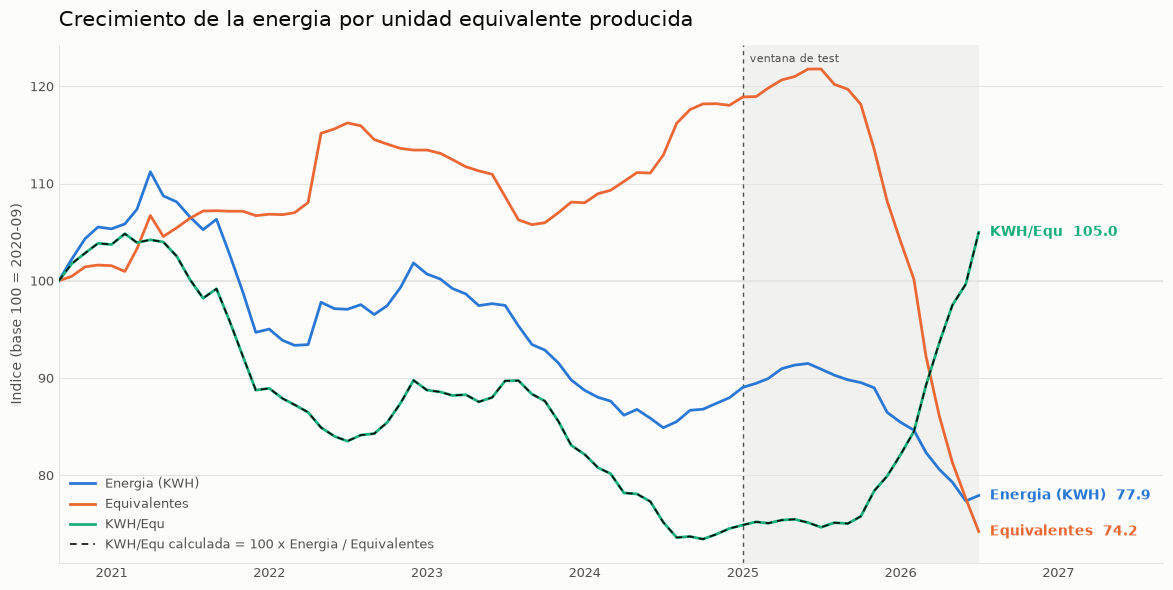

In [38]:
# Paleta validada (skill dataviz, slots 1-3, --pairs all)
C_ENERGIA, C_EQUIV, C_RAZON = "#2a78d6", "#eb6834", "#1baf7a"
SUPERFICIE, TINTA, TINTA_SUAVE, GRILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e5e2"

fig, ax = plt.subplots(figsize=(12, 6), facecolor=SUPERFICIE)
ax.set_facecolor(SUPERFICIE)

ax.axhline(100, color=GRILLA, linewidth=1.5, zorder=1)
series = [
    ("Energia (KWH)", C_ENERGIA),
    ("Equivalentes", C_EQUIV),
    ("KWH/Equ", C_RAZON),
]
for nombre, color in series:
    ax.plot(idx.index, idx[nombre], color=color, linewidth=2, label=nombre, zorder=3)

# Curva combinada calculada: debe caer exactamente sobre KWH/Equ medido
ax.plot(
    idx.index,
    idx["KWH/Equ (calculada)"],
    color=TINTA,
    linewidth=1.2,
    linestyle=(0, (4, 3)),
    zorder=4,
    label="KWH/Equ calculada = 100 x Energia / Equivalentes",
)

# Etiquetas directas (obligatorias: el verde queda por debajo de 3:1 de contraste)
for nombre, color in series:
    y_final = idx[nombre].iloc[-1]
    ax.annotate(
        f"{nombre}  {y_final:,.1f}",
        xy=(idx.index[-1], y_final),
        xytext=(8, 0),
        textcoords="offset points",
        color=color,
        fontsize=10,
        fontweight="bold",
        va="center",
    )

# La banda queda dentro de los datos; las etiquetas directas viven en el margen
# de 14 meses que anade set_xlim, asi que no se solapan con ella.
marcar_test(ax, idx.index[0], idx.index[-1], etiqueta=True)

ax.set_title(
    "Crecimiento de la energia por unidad equivalente producida",
    fontsize=15,
    color=TINTA,
    loc="left",
    pad=14,
)
ax.set_ylabel(f"Indice (base 100 = {idx.index[0]:%Y-%m})", fontsize=10, color=TINTA_SUAVE)
ax.grid(axis="y", color=GRILLA, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(GRILLA)
ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
ax.set_xlim(idx.index[0], idx.index[-1] + pd.DateOffset(months=14))
ax.legend(loc="lower left", frameon=False, fontsize=9, labelcolor=TINTA_SUAVE)

plt.tight_layout()
plt.show()

In [39]:
# Metricas explicitas del resumen de abajo
final = idx.iloc[-1]
en_corte = idx.loc[idx.index < CORTE_TS].iloc[-1]  # ultimo mes de train
niveles = {"Energia (KWH)": energia, "Equivalentes": equiv, "KWH/Equ": razon}

metricas_energia = pd.DataFrame(
    [
        {
            "serie": nombre,
            "nivel_base": s.dropna().iloc[0],
            "nivel_final": s.dropna().iloc[-1],
            "indice_fin_train": en_corte[nombre],
            "cambio_fin_train_pct": en_corte[nombre] - 100,
            "indice_final": final[nombre],
            "cambio_pct": final[nombre] - 100,
        }
        for nombre, s in niveles.items()
    ]
).round(2)

# La identidad de la curva combinada, verificada y no asumida
identidad_ok = np.allclose(idx["KWH/Equ"], 100 * idx["Energia (KWH)"] / idx["Equivalentes"])
print(
    f"base={idx.index[0]:%Y-%m}  fin de train={en_corte.name:%Y-%m}  "
    f"final={idx.index[-1]:%Y-%m}  identidad_exacta={identidad_ok}"
)

# Ensamble frente a la suma de sus 4 lineas, mes a mes
por_mes = df_ensamble.assign(Mes_inicio=df_ensamble["Fecha"].dt.to_period("M").dt.to_timestamp())
for var in ["KWH por proceso", "Produccion (Equivalente)"]:
    tabla = por_mes.pivot_table(index="Mes_inicio", columns="Proceso", values=var)
    suma = tabla.drop(columns="Ensamble").sum(axis=1, min_count=1)
    comparable = suma.notna()
    desvio = ((suma - tabla["Ensamble"]).abs() / tabla["Ensamble"])[comparable].max()
    print(f"{var}: suma de lineas vs Ensamble en {comparable.sum()} meses, desvio max {desvio:.1e}")

metricas_energia

base=2020-09  fin de train=2024-12  final=2026-07  identidad_exacta=True
KWH por proceso: suma de lineas vs Ensamble en 82 meses, desvio max 3.1e-07
Produccion (Equivalente): suma de lineas vs Ensamble en 34 meses, desvio max 3.5e-16


,serie,nivel_base,nivel_final,indice_fin_train,cambio_fin_train_pct,indice_final,cambio_pct
0,Energia (KWH),297363.17,231689.67,87.97,-12.03,77.91,-22.09
1,Equivalentes,108242.25,80326.44,118.05,18.05,74.21,-25.79
2,KWH/Equ,2.75,2.88,74.52,-25.48,104.99,4.99


### Resumen: la mejora de la planta se pierde dentro de la ventana de test

Serie de planta (`Ensamble`), media movil de 12 meses, indice base 100 en 2020-09:

| serie | nivel base (2020-09) | nivel final (2026-07) | indice al cierre de train (2024-12) | indice final |
|---|---|---|---|---|
| Energia | 297,363 kWh/mes | 231,690 kWh/mes | 87.97 | **77.91** |
| Equivalentes | 108,242 | 80,326 | 118.05 | **74.21** |
| `KWH/Equ` | 2.75 | 2.88 | 74.52 | **104.99** |

**Hasta 2024-12 la planta mejoraba.** Producia un 18.05 % mas que en la base con un 12.03 %
menos de energia, y la energia por equivalente habia bajado a 74.52.

**Dentro de la ventana de test lo pierde todo.** La produccion cae de 118.05 a 74.21
mientras la energia solo baja de 87.97 a 77.91, y `KWH/Equ` sube de 74.52 a 104.99. El
saldo final es -22.09 % de energia, -25.79 % de produccion y **+4.99 %** de energia por
equivalente.

**Todo el deterioro esta en la banda gris.** Un modelo entrenado hasta 2024-12 solo vio la
etapa de mejora.

**La curva combinada cierra exacta** (el `assert` lo verifica), y `Ensamble` coincide con
la suma de sus cuatro lineas: en energia los 82 meses (desvio maximo 3.1e-07) y en
produccion los 34 meses en que las lineas reportan (3.5e-16).

## Series de tiempo por proceso

Se grafican las mismas 3 variables que en OREC, un cuadro por proceso:
`KWH por proceso`, `Produccion (Equivalente)` y `KWH/Equ (Reales)`. `Ensamble` es el total
de planta y va primero; las cuatro lineas son su desglose.

In [40]:
VARS_PROC = ["KWH por proceso", "Produccion (Equivalente)", "KWH/Equ (Reales)"]

# Fecha reparte el dia dentro del mes de forma artificial: se trabaja por inicio de mes
base_proc = df_ensamble.copy()
base_proc["Mes_inicio"] = base_proc["Fecha"].dt.to_period("M").dt.to_timestamp()

# Ensamble es el total de planta: va primero, luego las 4 lineas
PROCESOS = ["Ensamble", *sorted(set(base_proc["Proceso"]) - {"Ensamble"})]

# Un DataFrame Mes x Proceso por cada variable
series_proc = {
    v: base_proc.pivot_table(index="Mes_inicio", columns="Proceso", values=v, aggfunc="mean")[
        PROCESOS
    ]
    for v in VARS_PROC
}
print(f"{len(PROCESOS)} procesos | {len(series_proc[VARS_PROC[0]])} meses")
series_proc["KWH por proceso"].tail(3).round(1)

5 procesos | 82 meses


Proceso,Ensamble,Linea 1,Linea 2,Linea 3,Linea 4
Mes_inicio,,,,,
2026-05-01,230304.0,78303.4,43757.8,46060.8,62182.1
2026-06-01,198139.0,67367.3,37646.5,39627.8,53497.5
2026-07-01,279900.0,95166.0,53181.1,55980.0,75573.0


In [41]:
series_proc.keys()

dict_keys(['KWH por proceso', 'Produccion (Equivalente)', 'KWH/Equ (Reales)'])

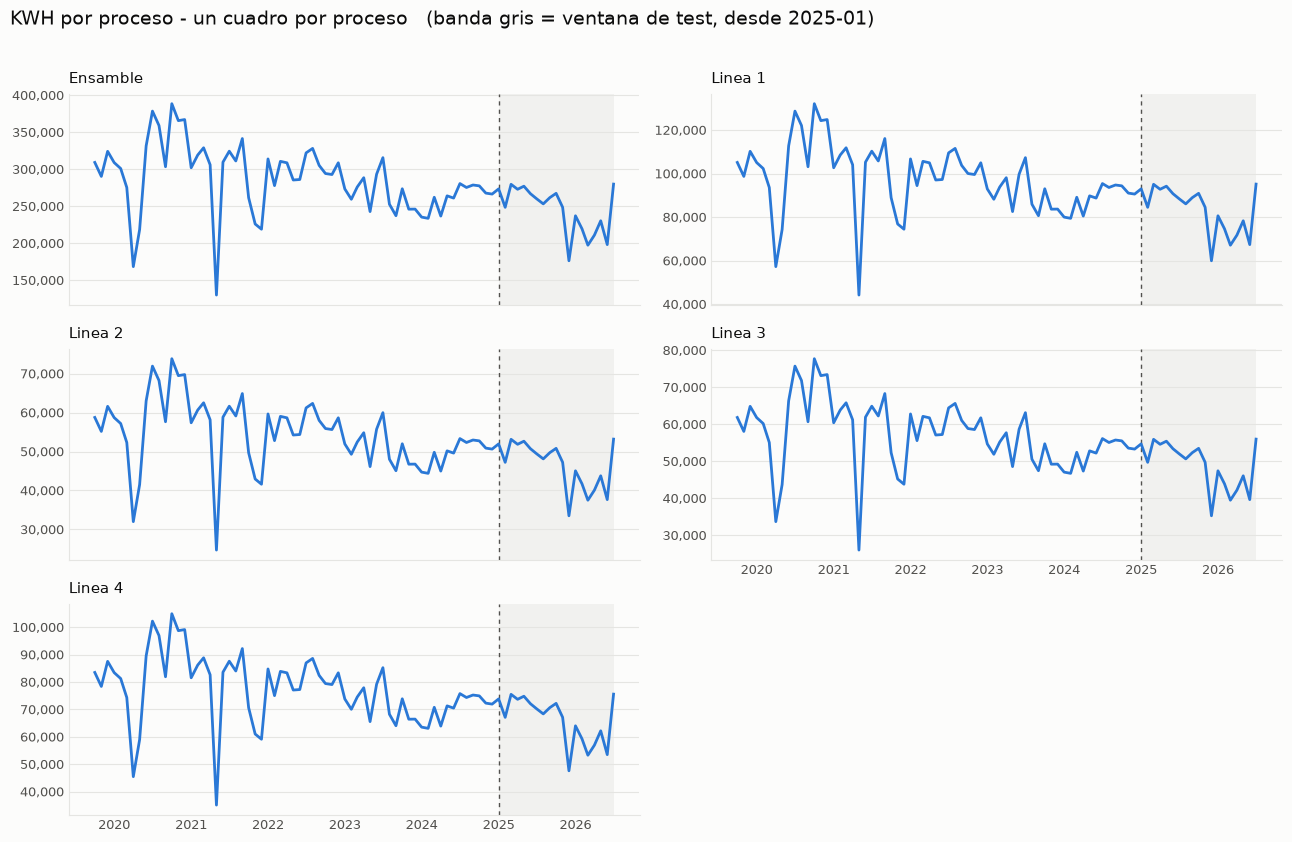

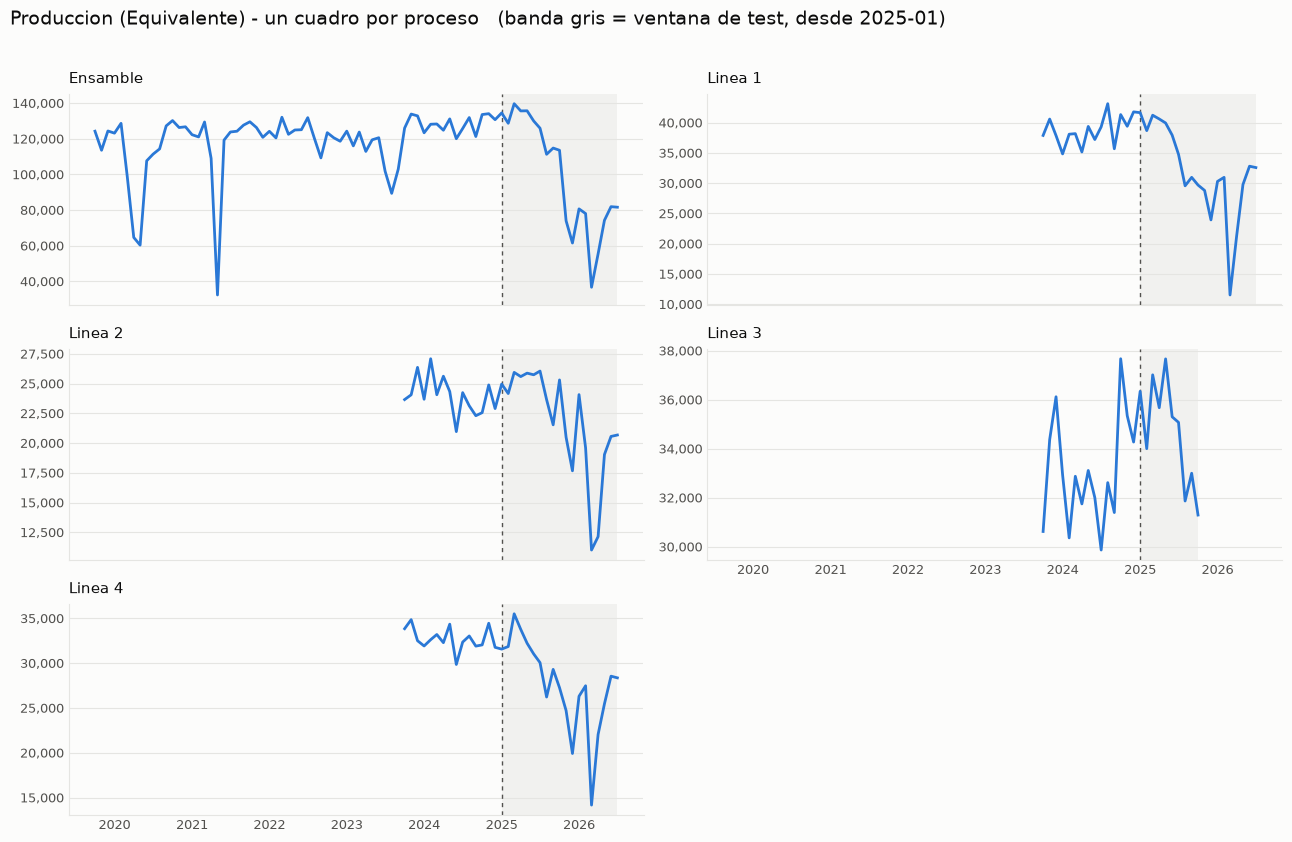

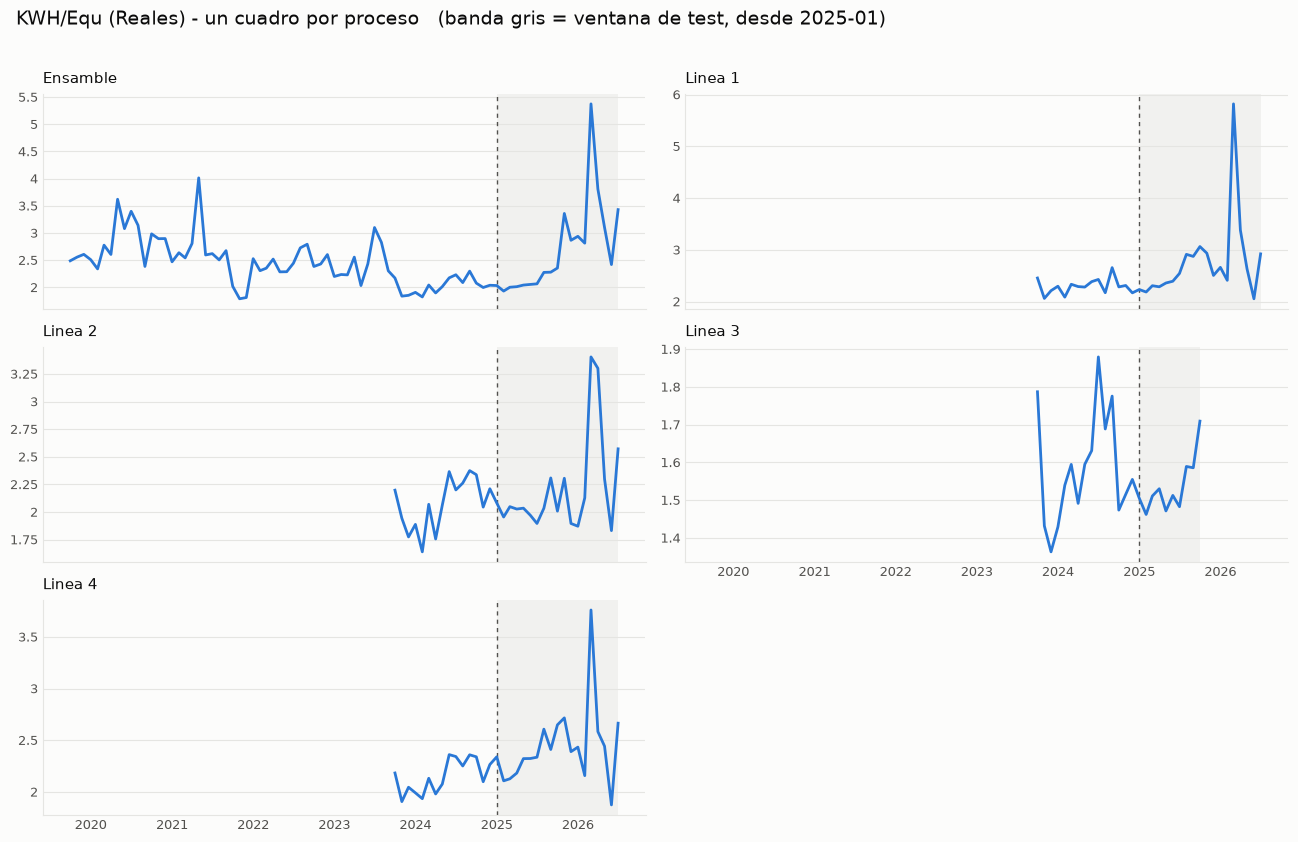

In [42]:
# Paleta validada (skill dataviz)
LINEA, SUPERFICIE = "#2a78d6", "#fcfcfb"
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e5e5e2"


def rejilla_procesos(titulo: str) -> tuple[plt.Figure, np.ndarray]:
    """Rejilla 3x2 con un cuadro por proceso (5 procesos, la 6a casilla se oculta)."""
    fig, axes = plt.subplots(3, 2, figsize=(13, 8.5), facecolor=SUPERFICIE, sharex=True)
    fig.suptitle(
        f"{titulo}   (banda gris = ventana de test, desde 2025-01)",
        fontsize=14,
        color=TINTA,
        x=0.01,
        ha="left",
        y=0.985,
    )
    for ax in axes.ravel():
        ax.set_facecolor(SUPERFICIE)
        ax.grid(axis="y", color=GRILLA, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_color(GRILLA)
        ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
        ax.yaxis.set_major_formatter(
            lambda v, _: f"{v:,.0f}" if abs(v) >= UMBRAL_MILES else f"{v:,.3g}"
        )
    axes.ravel()[-1].set_visible(False)
    # La casilla oculta era la que llevaba las fechas de la columna derecha: se le
    # devuelven al ultimo cuadro visible de esa columna
    axes[-2, -1].tick_params(labelbottom=True)
    return fig, axes


# Una figura por variable; dentro, un cuadro por proceso
for var in VARS_PROC:
    tabla = series_proc[var]
    fig, axes = rejilla_procesos(f"{var} - un cuadro por proceso")
    for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
        s = tabla[proc].replace(0, np.nan)  # el cero aqui es 'sin produccion registrada'
        ax.plot(s.index, s, color=LINEA, linewidth=2, zorder=3)
        ax.set_title(proc, fontsize=10.5, color=TINTA, loc="left", pad=8)
    # sharex=True: todos los cuadros comparten el eje, se sombrea una vez por eje
    for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
        s = tabla[proc].replace(0, np.nan).dropna()
        if not s.empty:
            marcar_test(ax, s.index[0], s.index[-1])
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

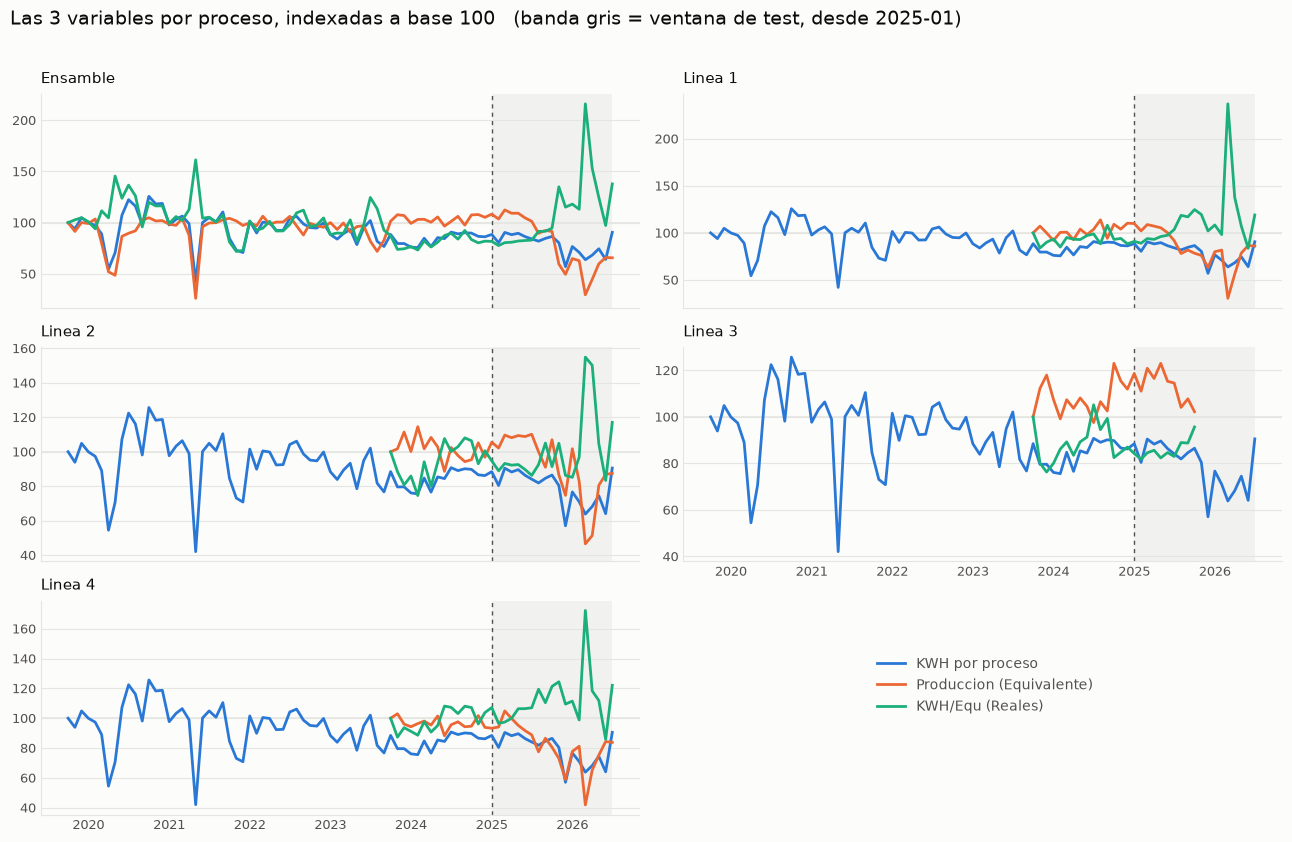

In [43]:
# Cuarta figura: un cuadro por proceso con las 3 variables indexadas a base 100,
# unica forma de verlas juntas (escalas de ~10^5, ~10^4 y ~2)
C_ENERGIA, C_EQUIV, C_RAZON = "#2a78d6", "#eb6834", "#1baf7a"

fig, axes = rejilla_procesos("Las 3 variables por proceso, indexadas a base 100")
for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    for var, color in zip(VARS_PROC, [C_ENERGIA, C_EQUIV, C_RAZON], strict=False):
        s = series_proc[var][proc].replace(0, np.nan).dropna()
        if s.empty:
            continue
        ax.plot(s.index, 100 * s / s.iloc[0], color=color, linewidth=2, label=var, zorder=3)
    ax.axhline(100, color=GRILLA, linewidth=1.2, zorder=1)
    ax.set_title(proc, fontsize=10.5, color=TINTA, loc="left", pad=8)

for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    vistos = [series_proc[v][proc].replace(0, np.nan).dropna() for v in VARS_PROC]
    vistos = [s for s in vistos if not s.empty]
    if vistos:
        marcar_test(ax, min(s.index[0] for s in vistos), max(s.index[-1] for s in vistos))

# La leyenda va en la casilla vacia de la rejilla, donde no tapa ninguna serie
manijas, rotulos = axes.ravel()[0].get_legend_handles_labels()
fig.legend(
    manijas,
    rotulos,
    loc="center",
    bbox_to_anchor=(0.76, 0.19),
    frameon=False,
    fontsize=10,
    labelcolor=TINTA_SUAVE,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [44]:
# Metricas explicitas del resumen de abajo
filas = []
for proc in PROCESOS:
    es_proc = df_ensamble["Proceso"] == proc
    fila = {
        "proceso": proc,
        # Indice: la fraccion de la energia de planta que se le asigna a cada proceso
        "indice_min": df_ensamble.loc[es_proc, "Indice"].min(),
        "indice_max": df_ensamble.loc[es_proc, "Indice"].max(),
    }
    for var in VARS_PROC:
        s = series_proc[var][proc].replace(0, np.nan).dropna()
        fila[f"{var} | meses"] = len(s)
        fila[f"{var} | desde"] = s.index.min().strftime("%Y-%m") if len(s) else "-"
        fila[f"{var} | hasta"] = s.index.max().strftime("%Y-%m") if len(s) else "-"
    filas.append(fila)

metricas_series_proc = pd.DataFrame(filas)

# La energia por proceso no se mide: es la energia de planta por ese Indice
reparto = df_ensamble["Indice"] * df_ensamble["KWH"]
error_reparto = (
    (reparto - df_ensamble["KWH por proceso"]).abs() / df_ensamble["KWH por proceso"]
).max()
indice_lineas = metricas_series_proc.loc[
    metricas_series_proc["proceso"] != "Ensamble", "indice_max"
]
print(f"KWH por proceso = Indice x KWH -> error relativo maximo {error_reparto:.1e}")
print(f"los Indice de las lineas suman {indice_lineas.sum():.2f}")

# Que variables cambian de un proceso a otro dentro del mismo mes
mes_proc = df_ensamble["Fecha"].dt.to_period("M")
varia = df_ensamble.groupby(mes_proc)[num_cols].nunique().gt(1).sum()
print("meses en que la variable difiere entre procesos:")
print(varia.to_string())

metricas_series_proc

KWH por proceso = Indice x KWH -> error relativo maximo 6.4e-16
los Indice de las lineas suman 1.00
meses en que la variable difiere entre procesos:
Indice                      82
KWH                          0
KWH por proceso             82
Produccion (Equivalente)    34
KWH/Equ (Reales)            82
KWH/Equ (Presupuesto)       10
Costo por KWH                0
Costo total KWH             24


,proceso,indice_min,indice_max,KWH por proceso | meses,KWH por proceso | desde,KWH por proceso | hasta,Produccion (Equivalente) | meses,Produccion (Equivalente) | desde,Produccion (Equivalente) | hasta,KWH/Equ (Reales) | meses,KWH/Equ (Reales) | desde,KWH/Equ (Reales) | hasta
0,Ensamble,1.00,1.00,82,2019-10,2026-07,82,2019-10,2026-07,82,2019-10,2026-07
1,Linea 1,0.34,0.34,82,2019-10,2026-07,34,2023-10,2026-07,34,2023-10,2026-07
2,Linea 2,0.19,0.19,82,2019-10,2026-07,34,2023-10,2026-07,34,2023-10,2026-07
3,Linea 3,0.20,0.20,82,2019-10,2026-07,25,2023-10,2025-10,25,2023-10,2025-10
4,Linea 4,0.27,0.27,82,2019-10,2026-07,34,2023-10,2026-07,34,2023-10,2026-07


### Resumen: series por proceso

- **La energia por linea no se mide, se reparte.** `KWH por proceso` es exactamente
  `Indice x KWH` (error relativo maximo 6.4e-16) y el `Indice` de cada linea no cambia en
  toda la historia: 0.34, 0.19, 0.20 y 0.27, que suman 1.00. Por eso los cuadros de energia
  de las cuatro lineas tienen la misma forma que el de planta.
- **La produccion por linea si es un dato propio**, pero solo desde 2023-10: 34 meses
  frente a los 82 de `Ensamble`.
- **`Linea 3` deja de producir.** Tiene 25 meses con produccion y el ultimo es 2025-10; las
  otras tres llegan a 2026-07.
- **Aqui cambian de un proceso a otro mas variables que en OREC**: ademas de las tres
  graficadas, `Indice` (los 82 meses), `Costo total KWH` (24) y `KWH/Equ (Presupuesto)`
  (10). Solo `KWH` y `Costo por KWH` son cifras de planta repetidas en las 5 filas.

## Crecimiento de la energia por proceso

Misma descomposicion que a nivel de planta, ahora un cuadro por proceso. La ventana de
suavizado se adapta a la cobertura: **12 meses para `Ensamble`** y **3 meses para las
lineas**, que solo reportan produccion desde 2023-10.

In [45]:
# Ensamble reutiliza el indice ya calculado en la seccion de planta (`idx`), para que no
# existan dos cifras distintas de lo mismo en el notebook. Las lineas se calculan aparte
# con ventana de 3 meses, desde el primer mes con produccion registrada.
VENTANA_PLANTA, VENTANA_LINEA = 12, 3

crecimiento = {
    "Ensamble": idx[["Energia (KWH)", "Equivalentes", "KWH/Equ"]].rename(
        columns={"Energia (KWH)": "Energia"}
    )
}

for proc in [x for x in PROCESOS if x != "Ensamble"]:
    e = series_proc["KWH por proceso"][proc]
    # Produccion 0 = linea detenida. Se deja como faltante: si entra a la media movil,
    # la ventana llega a cero y la razon energia/produccion divide por el.
    q = series_proc["Produccion (Equivalente)"][proc].replace(0, np.nan)
    inicio = q.dropna().index.min()  # desde que se mide produccion en esta linea
    e = e.loc[inicio:].rolling(VENTANA_LINEA).mean()
    q = q.loc[inicio:].rolling(VENTANA_LINEA).mean()
    comun = e.dropna().index.intersection(q.dropna().index)
    e, q = e.loc[comun], q.loc[comun]
    r = e / q
    crecimiento[proc] = pd.DataFrame(
        {
            "Energia": 100 * e / e.iloc[0],
            "Equivalentes": 100 * q / q.iloc[0],
            "KWH/Equ": 100 * r / r.iloc[0],
        }
    )

filas = []
for proc, tabla in crecimiento.items():
    produccion = series_proc["Produccion (Equivalente)"][proc]
    detenida = produccion == 0  # meses con registro de produccion igual a cero
    filas.append(
        {
            "proceso": proc,
            "ventana_meses": VENTANA_PLANTA if proc == "Ensamble" else VENTANA_LINEA,
            "puntos": len(tabla),
            "desde": tabla.index.min().strftime("%Y-%m"),
            "hasta": tabla.index.max().strftime("%Y-%m"),
            "energia_idx": tabla["Energia"].iloc[-1],
            "equivalentes_idx": tabla["Equivalentes"].iloc[-1],
            "kwh_equ_idx": tabla["KWH/Equ"].iloc[-1],
            # Energia que se le asigna en meses en que no produjo nada
            "meses_sin_produccion": int(detenida.sum()),
            "kwh_asignados_sin_produccion": series_proc["KWH por proceso"][proc][detenida].sum(),
        }
    )
metricas_crecimiento_proc = pd.DataFrame(filas).round(1)

# La identidad combinada tiene que cerrar en cada proceso
assert all(
    np.allclose(t["KWH/Equ"], 100 * t["Energia"] / t["Equivalentes"]) for t in crecimiento.values()
), "la identidad no cierra en algun proceso"
metricas_crecimiento_proc

,proceso,ventana_meses,puntos,desde,hasta,energia_idx,equivalentes_idx,kwh_equ_idx,meses_sin_produccion,kwh_asignados_sin_produccion
0,Ensamble,12,71,2020-09,2026-07,77.9,74.2,105.0,0,0.0
1,Linea 1,3,32,2023-12,2026-07,92.5,81.8,113.1,0,0.0
2,Linea 2,3,32,2023-12,2026-07,92.5,81.4,113.7,0,0.0
3,Linea 3,3,23,2023-12,2025-10,102.1,95.1,107.4,9,399614.8
4,Linea 4,3,32,2023-12,2026-07,92.5,81.4,113.6,0,0.0


In [46]:
crecimiento.keys()

dict_keys(['Ensamble', 'Linea 1', 'Linea 2', 'Linea 3', 'Linea 4'])

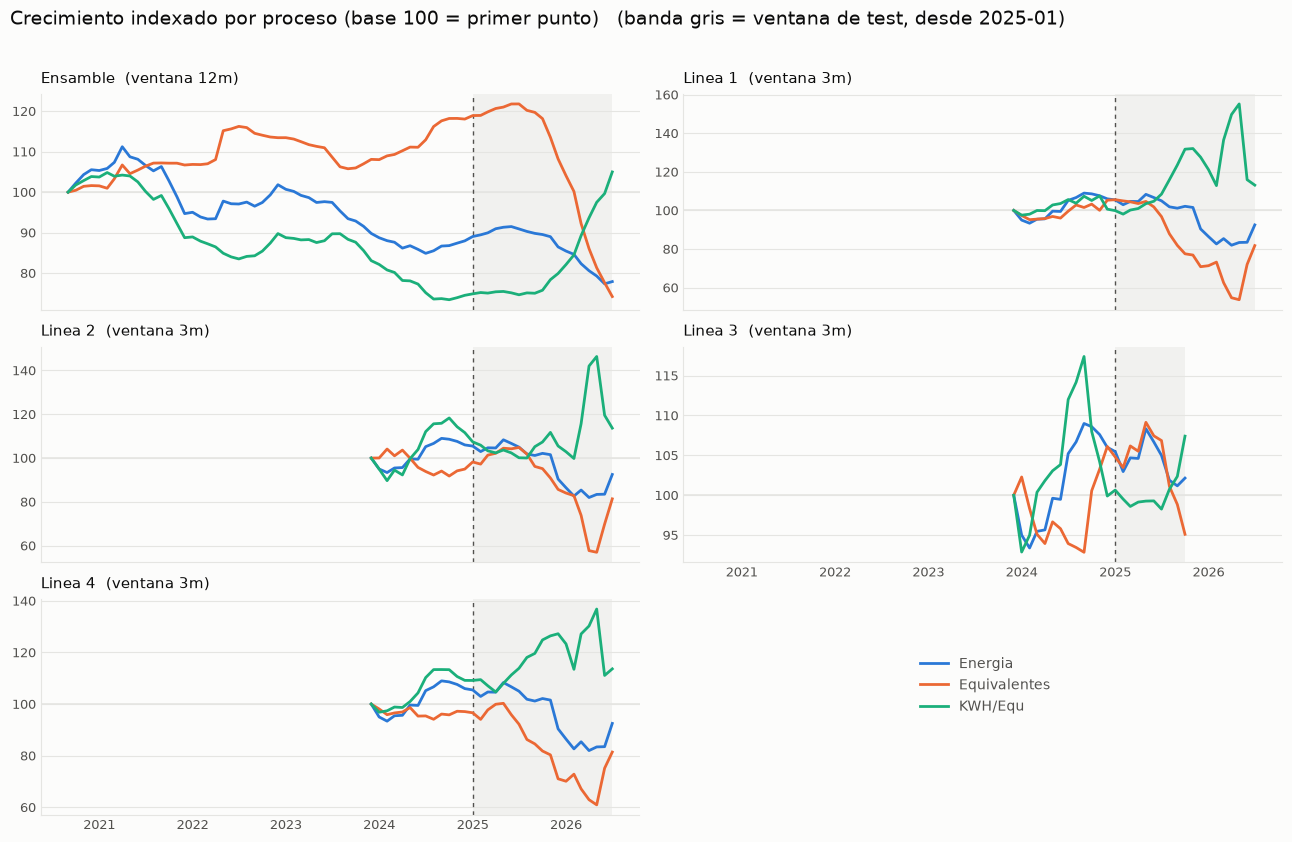

In [47]:
fig, axes = rejilla_procesos("Crecimiento indexado por proceso (base 100 = primer punto)")
for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    tabla = crecimiento[proc]
    for col, color in zip(
        ["Energia", "Equivalentes", "KWH/Equ"], [C_ENERGIA, C_EQUIV, C_RAZON], strict=False
    ):
        ax.plot(tabla.index, tabla[col], color=color, linewidth=2, label=col, zorder=3)
    ax.axhline(100, color=GRILLA, linewidth=1.2, zorder=1)
    # cada panel termina en una fecha distinta (Linea 3 deja de producir en 2025)
    marcar_test(ax, tabla.index[0], tabla.index[-1])
    ventana = VENTANA_PLANTA if proc == "Ensamble" else VENTANA_LINEA
    ax.set_title(f"{proc}  (ventana {ventana}m)", fontsize=10.5, color=TINTA, loc="left", pad=8)

# La leyenda va en la casilla vacia de la rejilla, donde no tapa ninguna serie
manijas, rotulos = axes.ravel()[0].get_legend_handles_labels()
fig.legend(
    manijas,
    rotulos,
    loc="center",
    bbox_to_anchor=(0.76, 0.19),
    frameon=False,
    fontsize=10,
    labelcolor=TINTA_SUAVE,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Resumen: crecimiento por proceso

| proceso | energia | equivalentes | `KWH/Equ` |
|---|---|---|---|
| `Ensamble` (planta, 12m) | 77.9 | 74.2 | **105.0** |
| `Linea 1` | 92.5 | 81.8 | 113.1 |
| `Linea 2` | 92.5 | 81.4 | 113.7 |
| `Linea 3` (hasta 2025-10) | 102.1 | 95.1 | 107.4 |
| `Linea 4` | 92.5 | 81.4 | 113.6 |

- **El indice de energia es el mismo en las lineas 1, 2 y 4 (92.5)** porque su energia es
  una fraccion fija de la de planta. Lo unico que las distingue es la produccion.
- **Las tres perdieron produccion** (indices de 81.4 a 81.8), y por eso su energia por
  equivalente sube a entre 113.1 y 113.7.
- **`Linea 3` se detiene**: 9 meses con produccion cero, en los que se le siguieron
  asignando 399,614.8 kWh. Con un reparto fijo no se puede saber si esa energia la consumio
  de verdad `Linea 3` o las otras lineas, asi que el `KWH/Equ` por linea deja de ser fiable
  despues de 2025-10, su ultimo mes con produccion (puede que sea un error de imputacion humano).
- Las ventanas no son comparables entre si: `Ensamble` cubre 2020-09 a 2026-07 con ventana
  de 12 meses y las lineas desde 2023-12 con ventana de 3.



En general la planta y el desgloce por linea muestran como se bajo la producción y el consumo, sin embargo la producción baja mas rapido que el consumo de ahí que `KWH/Equ` aumente, esto es un posible problema en el cual se debe ahondar mas para buscar sus causas.